# Bitcoin's Realized Volatility Forecasting with GARCH and Multivariate LSTM


## Overview

Since Bitcoin's first appearance in 2009, it has changed the world's financial landscape substantially. The decentralized cryptocurrency has established itself as an asset class recognized by many asset managers, large investment banks and hedge funds. As the speed of mainstream adoption continues to soar, it is also leading investors to explore new ventures, such as crypto options and futures.

Bitcoin has been historically known to be more volatile than regulated stocks and commodities. Its most recent surge in late December 2020, early January 2021 has brought about a lot of questions and uncertainties about the future financial landscape. At the point of writing this report (end of August 2021), Bitcoin is traded at slightly below USD 50,000, which is no small feat considering it entered 2020 at around USD 7,200. 

The purpose of this project is to take a sneak peek into the future by **forecasting the next 7 days' average daily Realized Volatility (RV) of BTC-USD** using 2 different approaches - the traditional econometric approach to volatility prediction of financial time series **GARCH** and state-of-the-art **LSTM Neural Networks**.

## Business Problem

Volatility attempts to measure magnitude of price movements that a financial instrument experiences over a certain period of time. The more dramatic the price swings are in that instrument, the higher the level of volatility, and vice versa.

Volatility is generally accepted as the best measure of market risk and volatility forecasting is used in many different applications across the industry. **Realized Volatility Forecasting** models are typically utilized in risk management, market making, portfolio optimization, and option trading. Specifically, according to Sinclair (2020), a number of trading strategies evolve around identifying situations where this volatility mismatch occurs:

\begin{align*}
P/L = Vega|\sigma_{implied} - \sigma_{realized}|
\end{align*}

in which Vega is the measurement of an option's price sensitivity to changes in the volatility of the underlying asset, and $\sigma$ is volatility.
As Implied Volatility (IV) could be derived from Option Prices using models such as the Black Scholes Model, forecasting Realized Volatility would give us the key to the second part of the equation.

Although the forecasting and modeling of volatility has been the focus of many empirical studies and theoretical investigations in academia, forecasting volatility accurately remains a crucial challenge for scholars. On top of that, since crypto option trading is relatively new, there has not been as much research done on this Bitcoin volatility forecasting. In addition, crytocurrencies carry certain nuances that differ themselves from traditional regulated stocks and commodities, which would also need to be accounted for.

## Dataset

The historical dataset of Bitcoin Open/Close/High/Low prices were obtained using the Yahoo Finance API **`yfinance`**. This API is free, very easy to set up, but yet still contains a wide range of data and offerings. 

I will be downloading BTC-USD prices using ticker `BTC-USD` at 1-day interval. Yahoo did not add Bitcoin until 2014; and therefore although it was first traded in 2009, **`yfinance`** only contains data from September 2014 until now (August 2021). I would therefore be working with approx. 2,500 datapoints covering about 7 years of trading days.

### Installing & Importing Libraries 

(Please uncomment the 2 cells below to install `yfinance` and `arch` libraries if you don't already have them).

In [8]:
#!pip install arch
#!pip install numpy pandas matplotlib

In [9]:
#!pip3 install yfinance
#!pip install numpy
#!pip3 install --force-reinstall pandas numpy
#python.exe -m pip install --upgrade pip

In [868]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import date
from scipy import stats

%matplotlib inline

In [870]:
import warnings
warnings.filterwarnings('ignore')

In [872]:
import yfinance as yf

from datetime import datetime, timedelta
from sklearn.metrics import mean_squared_error as mse
from sklearn.preprocessing import MinMaxScaler
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

In [874]:
# Ref: https://towardsdatascience.com/8-commonly-used-pandas-display-options-you-should-know-a832365efa95
# ADJUST COLUMN WIDTH IN PANDAS TO SHOW ALL TEXT
# (FOR MODEL PERFORMANCE DISPLAY LATER)

pd.set_option('display.max_colwidth', None)

### Load Data from `yfinance`

In [877]:
# SET SEED FOR REPRODUCIBILITY
seed = 2026

In [879]:
# SELECT START AND END DATE
start = datetime(2021, 1, 1)
end = datetime(2025, 12, 31)


tckr = 'BTC-USD'

ticker = yf.Ticker(tckr)
df = ticker.history(start=start, 
                    end=end, 
                    interval="1d")

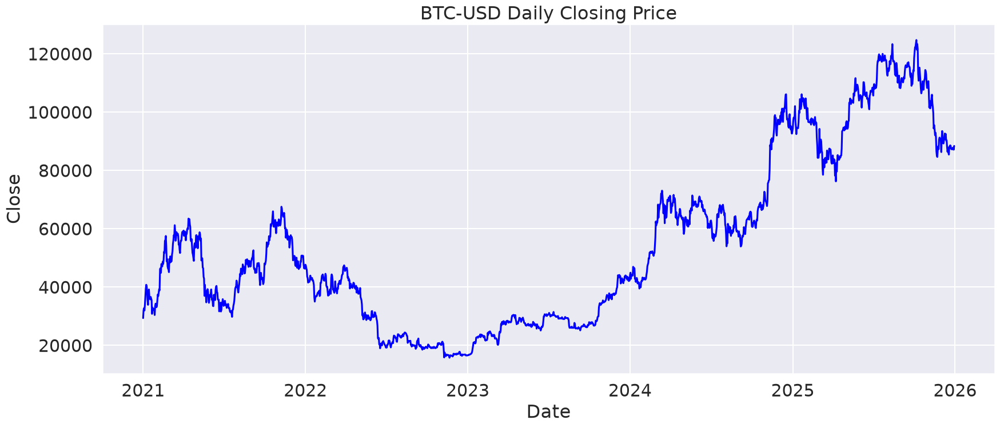

In [883]:
# CHANGE CONTEXT TO poster TO INCREASE FONT SIZES
sns.set_context("talk", font_scale=1.3)

# PLOT OUT BTC-USD'S CLOSING PRICES SINCE 2014
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,8))
    sns.lineplot(x=df.index, y=df.Close, color='blue')
    ax.set_title('BTC-USD Daily Closing Price')    

plt.tight_layout()
plt.show()
#plt.savefig(os.path.join(directory_to_img, 'close.png'), 
            #dpi=300, bbox_inches='tight');

In [885]:
# CALCULATE PRICE RETURNS AS DAILY PERCENTAGE CHANGE USING pct_change()
df['returns'] = 100 * df.Close.pct_change().dropna()

For practicality purposes, it's generally preferable to use the log returns especially in mathematic modeling, because it helps eliminate non-stationary properties of time series data, and makes it more stable:


LOG RETURNS FORMULA:

$r_{t, t+i} = log(P_{t+i} / P_{t})$

There's another advantage to log returns, which is that they're additive across time: $r_{t1, t2} + r_{t2, t3} = r_{t1, t3}$


In [888]:
# CALCULATE LOG RETURNS BASED ON ABOVE FORMULA
df['log_returns'] = np.log(df.Close/df.Close.shift(1))

In [890]:
df.index = df.index.date
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns
2021-01-01,28994.009766,29600.626953,28803.585938,29374.152344,40730301359,0.0,0.0,NaN,NaN
2021-01-02,29376.455078,33155.117188,29091.181641,32127.267578,67865420765,0.0,0.0,9.372578,0.089590
2021-01-03,32129.408203,34608.558594,32052.316406,32782.023438,78665235202,0.0,0.0,2.038007,0.020175
2021-01-04,32810.949219,33440.218750,28722.755859,31971.914062,81163475344,0.0,0.0,-2.471200,-0.025022
2021-01-05,31977.041016,34437.589844,30221.187500,33992.429688,67547324782,0.0,0.0,6.319658,0.061280


In [901]:
df.head()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns
2021-01-02,29376.455078,33155.117188,29091.181641,32127.267578,67865420765,0.0,0.0,9.372578,0.089590
2021-01-03,32129.408203,34608.558594,32052.316406,32782.023438,78665235202,0.0,0.0,2.038007,0.020175
2021-01-04,32810.949219,33440.218750,28722.755859,31971.914062,81163475344,0.0,0.0,-2.471200,-0.025022
2021-01-05,31977.041016,34437.589844,30221.187500,33992.429688,67547324782,0.0,0.0,6.319658,0.061280
2021-01-06,34013.613281,36879.699219,33514.035156,36824.363281,75289433811,0.0,0.0,8.331071,0.080022


In [892]:
# DROPPING THE 1ST ROW OF DATA 
# BECAUSE I SHIFTED IT FORWARD TO CALCULATE RETURNS/LOG RETURNS
df.dropna(inplace=True)

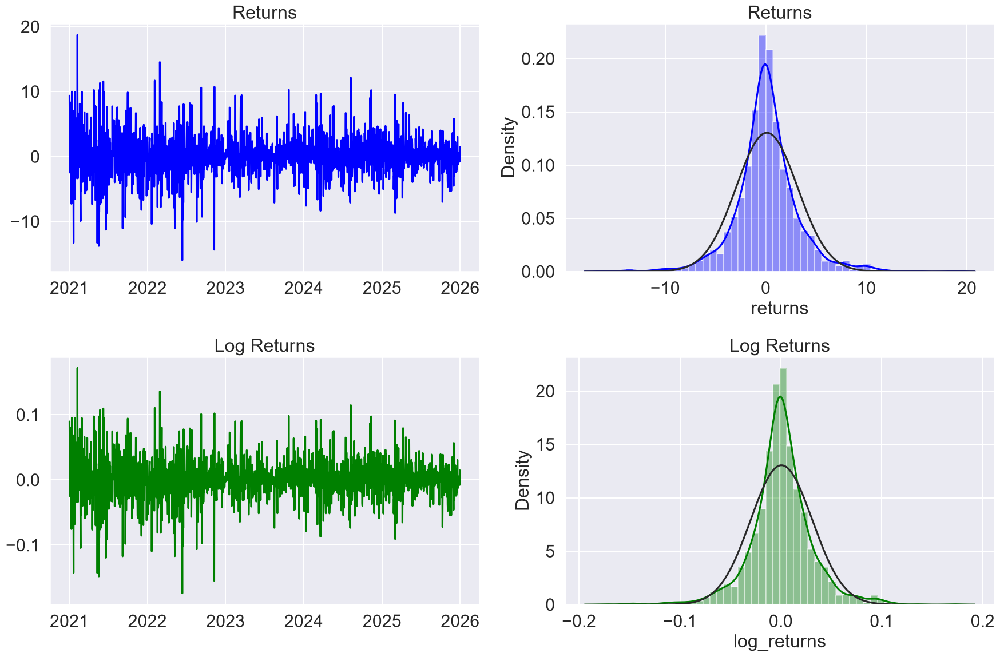

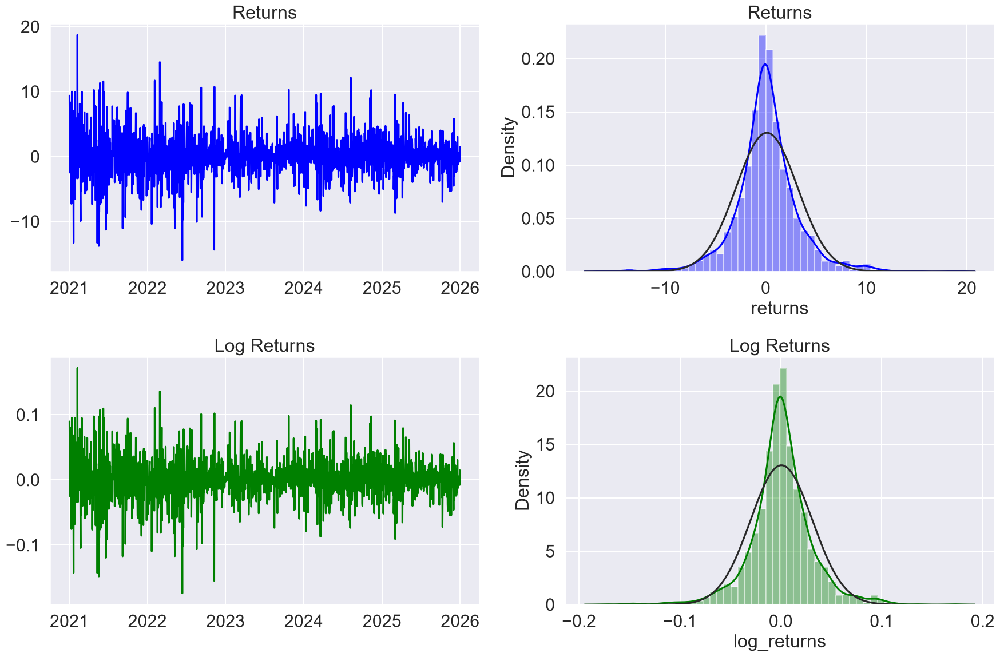

In [896]:
# PLOT DISTRIBUTION PLOTS OF RETURNS & LOG RETURNS
# AND VISUALLY COMPARE THEM WITH THE STANDARD NORMAL DISTRIBUTION
with sns.axes_style("darkgrid"):
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18,12))

    axes[0][0].plot(df.returns, color='blue')
    axes[0][0].set_title('Returns')

    sns.distplot(df.returns, norm_hist=True, fit=stats.norm, color='blue',
                bins=50, ax=axes[0][1])
    axes[0][1].set_title('Returns')

    axes[1][0].plot(df.log_returns, color='green')
    axes[1][0].set_title('Log Returns')

    sns.distplot(df.log_returns, norm_hist=True, fit=stats.norm, color='green',
                bins=50, ax=axes[1][1])
    axes[1][1].set_title('Log Returns')
    plt.tight_layout()
   # plt.savefig(os.path.join(directory_to_img, 'returns_logreturns.png'), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

Both Returns & Log Returns show some:
- slight negative skewness
- positive kurtosis (leptokurtic) - higher peak with thicker tails than the standard normal distribution.


In [903]:
df.returns.describe()

count    1824.000000
mean        0.107188
std         3.060054
min       -15.974726
25%        -1.318294
50%        -0.000802
75%         1.491707
max        18.746474
Name: returns, dtype: float64

In [905]:
df.log_returns.describe()

count    1824.000000
mean        0.000604
std         0.030588
min        -0.174053
25%        -0.013271
50%        -0.000008
75%         0.014807
max         0.171821
Name: log_returns, dtype: float64

(Source: https://www.investopedia.com/articles/investing/102715/computing-historical-volatility-excel.asp)

The standard deviation will be different for log returns computed over longer or shorter intervals. For this specific project, the volatility would be for a certain fixed interval window (`INTERVAL_WINDOW`) is the standard deviation of log returns, or the square root of the sum of squares of log returns:

$\sigma_{interval} = \sqrt{\sum_{t} r_{t-1, t}^2}$

And then to scale the daily volatility by a certain frequency (weekly, monthly, yearly), we can multiply the daily volatility by the square root of that frequency in terms of day divided by the interval minus 1 (`INTERVAL_WINDOW - 1`). For example:

$\sigma_{daily} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{1}{interval-1}}$

$\sigma_{annualized} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{365}{interval-1}}$

$\sigma_{monthly} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{30}{interval-1}}$

$\sigma_{weekly} = \sqrt{\sum_{t} r_{t-1, t}^2} * \sqrt{\frac{7}{interval-1}}$


In [908]:
# CREATE A FUNCTION THAT CALCULATE REALIZED VOLATILITY
# FROM SAILY LOG RETURNS
def realized_volatility_daily(series_log_return):
    """
    Get the daily realized volatility which is calculated as the square root
    of sum of squares of log returns within a specific window interval 
    """
    n = len(series_log_return)
    return np.sqrt(np.sum(series_log_return**2)/(n - 1))

### Interval Window Selection

For this specific project I'll use an **interval window of 30 days** (equivalent to roughly 1 month of trading for cryptocurrencies). The goal here is to **forecast the average realized volatility of the next `n_future` 7 days** using all previous available datapoint with GARCH models (expanding window forecasting), and using a number of immediate past/historical datapoints (`n_past`) with Neural Networks (sliding window forecasting). 


In [911]:
intervals = [7, 30, 60, 180, 365]
vols_df = {}

# ITERATE OVER intervals LIST
for i in intervals:
    # GET DAILY LOG RETURNS USING THAT INTERVAL
    vols = df.log_returns.rolling(window=i)\
                         .apply(realized_volatility_daily).values

    vols_df[i] = vols

# CONVERT vols_df FROM DICTIONARY TO PANDAS DATAFRAME
vols_df = pd.DataFrame(vols_df, columns=intervals, index=df.index)

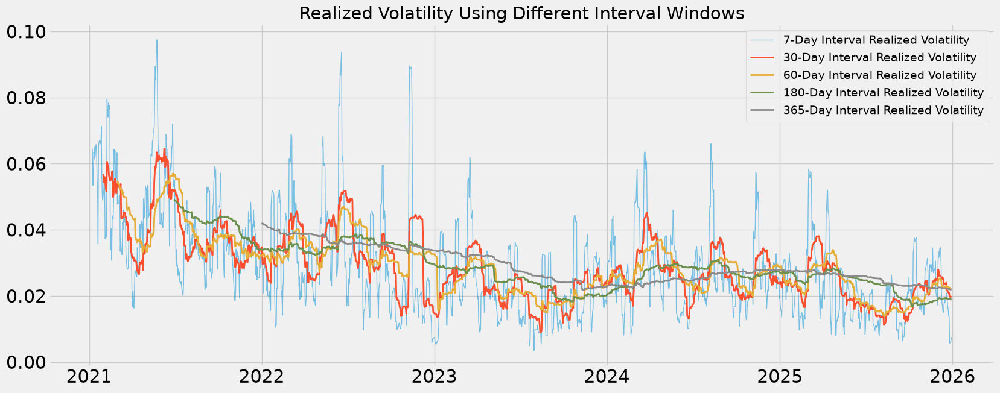

In [912]:
# CHANGING MATPLOTLIB STYLE
plt.style.use(['fivethirtyeight'])

fig, ax = plt.subplots(figsize=(18,7))

for i in intervals:
    if i == 7:
        alpha = 0.5
        lw = 1
    else:
        alpha = 1.0
        lw = 2
    ax.plot(vols_df[i], label=f'{i}-Day Interval Realized Volatility', 
            alpha=alpha, lw=lw)

ax.set_title('Realized Volatility Using Different Interval Windows', fontsize=21)

plt.legend(loc='best', prop={'size': 14})
#plt.savefig(os.path.join(directory_to_img, 'diff_intervals.png'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

The reason I selected 30 days is because 7 days seems too noisy to observe meaningful patterns, while longer intervals seem to smooth the volatility down significantly and tend to revert back to the mean.

Using interval window of 30 days would also help avoid wasting too many datapoints at the beginning of the dataset.

Time-series forecasting models are the models that are capable to predict **future** values based on previously observed values. Target "**future**" data in this case is obtained by **shifting the current volatility backward** by the number of `n_future` lags. 

For example, respected to last week's Monday, this week's Monday is the "**future**"; therefore I just need to shift the volatility this week back by 7 days, and use it as the desired "**future**" output for last week's, which I would then use for Neural Networks training and model performance evaluation. 

In [916]:
INTERVAL_WINDOW = 30
n_future = 7

# GET BACKWARD LOOKING REALIZED VOLATILITY
df['vol_current'] = df.log_returns.rolling(window=INTERVAL_WINDOW)\
                                   .apply(realized_volatility_daily)

# GET FORWARD LOOKING REALIZED VOLATILITY 
df['vol_future'] = df.log_returns.shift(-n_future)\
                                 .rolling(window=INTERVAL_WINDOW)\
                                 .apply(realized_volatility_daily)

In [917]:
df.describe()

,Open,High,Low,Close,Volume,Dividends,Stock Splits,returns,log_returns,vol_current,vol_future
count,1824.000000,1824.000000,1824.000000,1824.000000,1.824000e+03,1824.0,1824.0,1824.000000,1824.000000,1795.000000,1788.000000
mean,54391.800959,55454.982482,53262.417431,54421.953754,3.717548e+10,0.0,0.0,0.107188,0.000604,0.029015,0.028914
std,29458.752734,29867.591748,29024.154602,29463.941588,2.306313e+10,0.0,0.0,3.060054,0.030588,0.010596,0.010495
min,15782.300781,16253.047852,15599.046875,15787.284180,5.331173e+09,0.0,0.0,-15.974726,-0.174053,0.009005,0.009005
25%,29393.954102,29979.005859,28977.500000,29405.761230,2.132605e+10,0.0,0.0,-1.318294,-0.013271,0.021515,0.021421
50%,46430.585938,47511.376953,45240.265625,46454.812500,3.178638e+10,0.0,0.0,-0.000802,-0.000008,0.026943,0.026865
75%,69045.736328,70055.468750,67548.808594,69126.505859,4.722553e+10,0.0,0.0,1.491707,0.014807,0.035045,0.034986
max,124752.140625,126198.070312,123196.046875,124752.531250,3.509679e+11,0.0,0.0,18.746474,0.171821,0.064581,0.064581


The 2 columns `Dividends` and `Stock Splits` don't store any information, all rows are `0.0`, so I'll remove them.

In [919]:
df = df.drop(['Dividends', 'Stock Splits'], axis=1)

In [920]:
df.describe()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
count,1824.000000,1824.000000,1824.000000,1824.000000,1.824000e+03,1824.000000,1824.000000,1795.000000,1788.000000
mean,54391.800959,55454.982482,53262.417431,54421.953754,3.717548e+10,0.107188,0.000604,0.029015,0.028914
std,29458.752734,29867.591748,29024.154602,29463.941588,2.306313e+10,3.060054,0.030588,0.010596,0.010495
min,15782.300781,16253.047852,15599.046875,15787.284180,5.331173e+09,-15.974726,-0.174053,0.009005,0.009005
25%,29393.954102,29979.005859,28977.500000,29405.761230,2.132605e+10,-1.318294,-0.013271,0.021515,0.021421
50%,46430.585938,47511.376953,45240.265625,46454.812500,3.178638e+10,-0.000802,-0.000008,0.026943,0.026865
75%,69045.736328,70055.468750,67548.808594,69126.505859,4.722553e+10,1.491707,0.014807,0.035045,0.034986
max,124752.140625,126198.070312,123196.046875,124752.531250,3.509679e+11,18.746474,0.171821,0.064581,0.064581


Since I am currently using an `INTERVAL_WINDOW` of 30 and a horizon `n_future` of  7, the volatilty of first 30 values as well as the last 7 values of the dataframe would be `NaN`, and therefore need to be dropped from the dataset.

In [922]:
# DROPPING ALL NaN VALUES
df.dropna(inplace=True)

## **Exploratory Data Analysis**

First I would just plot out my desired target outputs `vol_future` with respect to the current volatility `vol_current`. The first plot shows all the datapoints I have available that covers 7 years, but then the second plot is only zooming in the most recent 365 days.

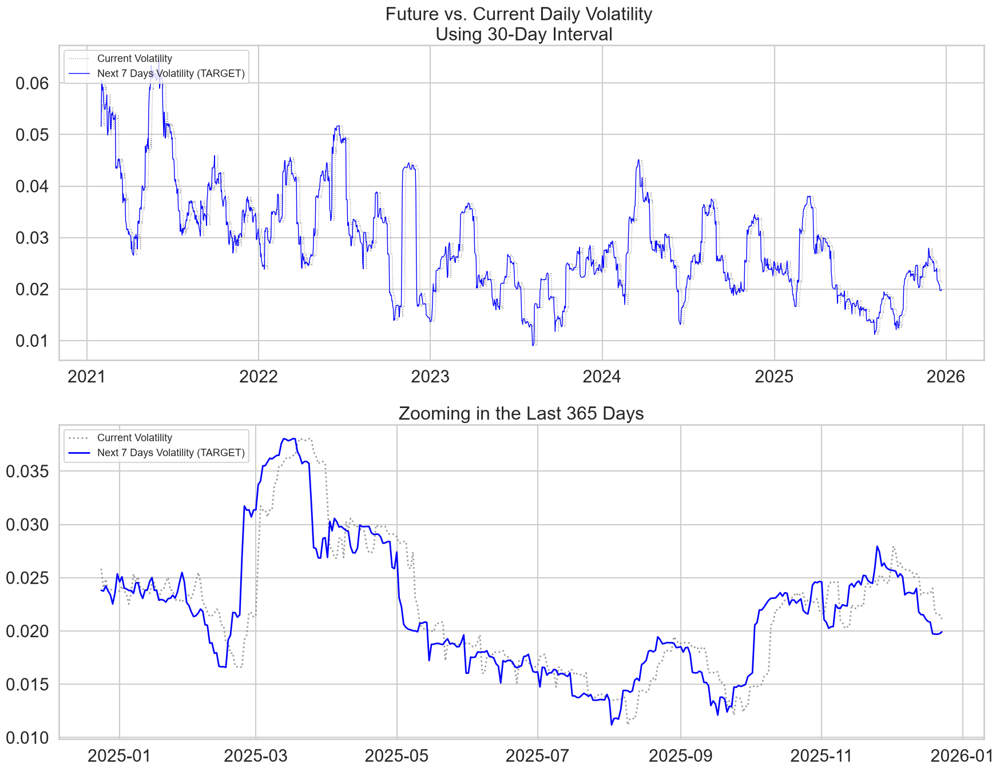

In [924]:
n_zoom = 365
sns.set_context("talk", font_scale=1.3)
# plt.style.use(['seaborn'])

# VISUALIZE REALIZED CURRENT VS. FUTURE VOLATILITY
with sns.axes_style("whitegrid"):
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(18,14))

    ax1.plot(df.vol_current, alpha=.8, lw=1, color='gray', ls=':',
            label='Current Volatility')
    ax1.plot(df.vol_future, lw=1, color='blue',
            label=f'Next {n_future} Days Volatility (TARGET)')

    ax2.plot(df.vol_current[-n_zoom:], alpha=.8, lw=2, color='gray', ls=':',
            label='Current Volatility')
    ax2.plot(df.vol_future[-n_zoom:], lw=2, color='blue',
            label=f'Next {n_future} Days Volatility (TARGET)')

    ax1.title.set_text(f'Future vs. Current Daily Volatility \n Using {INTERVAL_WINDOW}-Day Interval')
    ax2.title.set_text(f'Zooming in the Last {n_zoom} Days')

    ax1.legend(loc='upper left', prop={'size': 13}, frameon=True)
    ax2.legend(loc='upper left', prop={'size': 13}, frameon=True)
    plt.tight_layout()
    #plt.savefig(os.path.join(directory_to_img, 'daily_vol.jpg'), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

In the plot above, the **blue line** indicates the **target future** value that I ultimately try to match up to. 

And the dotted **gray line** represents the **current volatility** in real-time. 

This is a visualization of how current volatility is shifted backward to become future values, which I want to eventually aim for. 

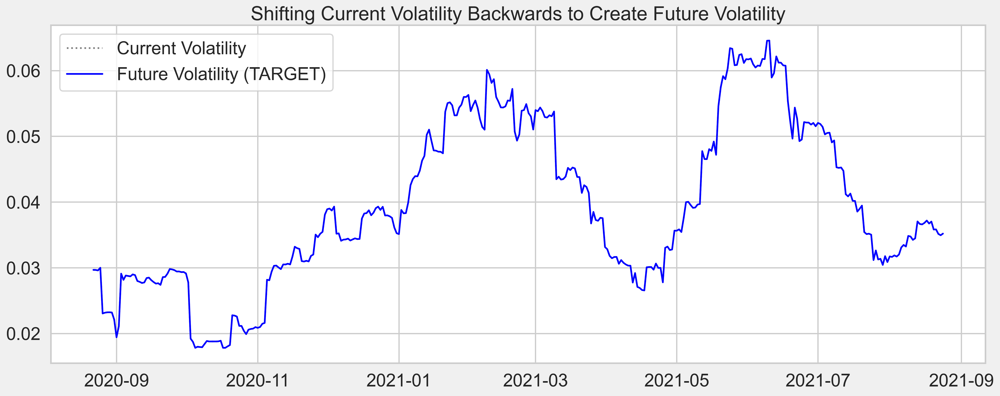

### **Daily Volatility Grouped by Month**

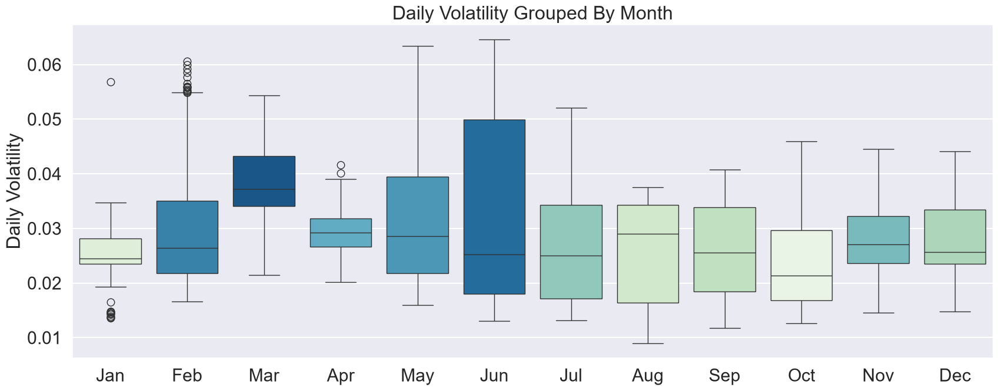

In [927]:
# PRESORT MONTHS IN CHRONOLOGICAL ORDER 
ordered_months = ['Jan', 'Feb', 'Mar', 'Apr','May','Jun', 
                  'Jul', 'Aug','Sep', 'Oct', 'Nov', 'Dec']

# Convert index to DatetimeIndex
df.index = pd.to_datetime(df.index)

# GROUP vol_current BY MONTH AND TAKE THE MEAN
data = df.groupby(by=[df.index.month_name()]).vol_current.mean()

# ABBREVIATE MONTH NAME
data.index = [x[:3] for x in data.index]

# SELECT PALETTE
pal = sns.color_palette("GnBu", len(data))

# SORT MONTH BY AVERAGE vol_current
rank = data.argsort().argsort().reindex(ordered_months)

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,7))
    
    sns.boxplot(x=[x[:3] for x in df.index.month_name()], 
                y=df.vol_current, 
                palette=np.array(pal)[rank],
                order=ordered_months)
    ax.set(xlabel='', 
           ylabel='Daily Volatility', 
           title='Daily Volatility Grouped By Month')
    #plt.savefig(os.path.join(directory_to_img, "vol_by_month.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show()

In [928]:
df.vol_current.sort_values(ascending=False)[:50]

2021-06-10    0.064581
2021-06-09    0.064561
2021-05-24    0.063431
2021-05-25    0.063327
2021-05-29    0.062509
2021-05-28    0.062399
2021-06-13    0.062170
2021-06-02    0.061850
2021-06-07    0.061786
2021-06-08    0.061761
2021-05-31    0.061754
2021-06-01    0.061718
2021-06-14    0.061227
2021-06-15    0.061221
2021-05-30    0.061178
2021-06-03    0.060983
2021-05-27    0.060874
2021-05-26    0.060834
2021-06-16    0.060804
2021-06-05    0.060782
2021-06-17    0.060761
2021-06-06    0.060722
2021-02-08    0.060580
2021-06-04    0.060484
2021-05-23    0.060347
2021-02-09    0.059923
2021-06-12    0.059614
2021-05-21    0.059169
2021-02-11    0.059166
2021-06-11    0.058957
2021-05-22    0.058699
2021-02-10    0.058604
2021-02-19    0.057700
2021-05-20    0.057460
2021-01-31    0.056789
2021-02-12    0.056477
2021-02-17    0.055952
2021-02-03    0.055952
2021-02-18    0.055904
2021-02-13    0.055763
2021-02-25    0.055407
2021-06-18    0.055367
2021-02-02    0.055249
2021-02-16 

It can be observed that:
- volatility has consistently reached some of its higher points in the in the months of December/January historically 
- March and April have the most amount of large outliers 
- while August and September (which are the upcoming months of the final testing forecast) historically has been relatively quiet

### **Daily Volatility Grouped by Year**

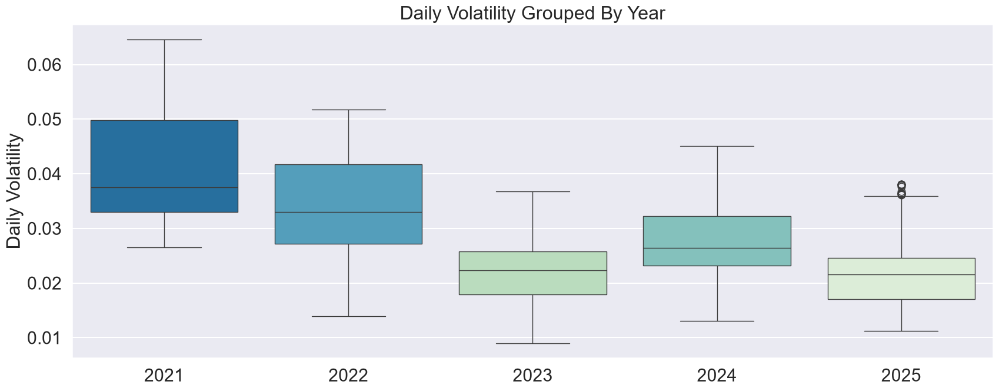

In [931]:
# GROUP vol_current BY YEAR AND TAKE THE MEAN
data = df.groupby(by=[df.index.year]).vol_current.mean()

# SELECT PALETTE
pal = sns.color_palette("GnBu", len(data))

# SORT MONTH BY AVERAGE vol_current
rank = data.argsort().argsort()

with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(18,7))
    
    sns.boxplot(x=df.index.year, 
                y=df.vol_current, 
                palette=np.array(pal)[rank])
    ax.set(xlabel='', 
           ylabel='Daily Volatility', 
           title='Daily Volatility Grouped By Year')
    #plt.savefig(os.path.join(directory_to_img, "vol_by_year.png"), 
   #             dpi=300, bbox_inches='tight')
    plt.show()

Cryptocurrencies have gone through some huge structural changes in the last few years that would've affected volatility directly, such as:
- Crypto Options became available on Deribit in 2016
- Bitcoin Futures was offered on CME in 2017
- and then CME Bitcoin Options in 2020

These events have allowed people to trade crypto volatility more efficiently, and therefore data pre-2016 are likely structurally different, and probably followed different patterns compared to data after 2016.

We can these big events being reflected in the plot above - Bitcoin's first record peak in 2017 (around USD 19,800 towards the end of December). And the outliers in 2020 corresponded with its over 200% surge in 2020 (Bitcoin started at USD 7,200 at the beginning of 2020). It reached USD 20,000 on most exchanges on 12/15/2020, and then proceeded to hit USD 30,000 just 17 days later, which is no small feat. To put things in perspective, it took the Dow Jones close to 3 years to make the same move. And then, on 01/07/2021 it broke USD 40,000. As of the time this report is written, BTC-USD is traded at high USD 49,700.

It can be observed that 2021's daily volatiliy overall has also been on the higher side. 

### **Daily Volatility Distribution**

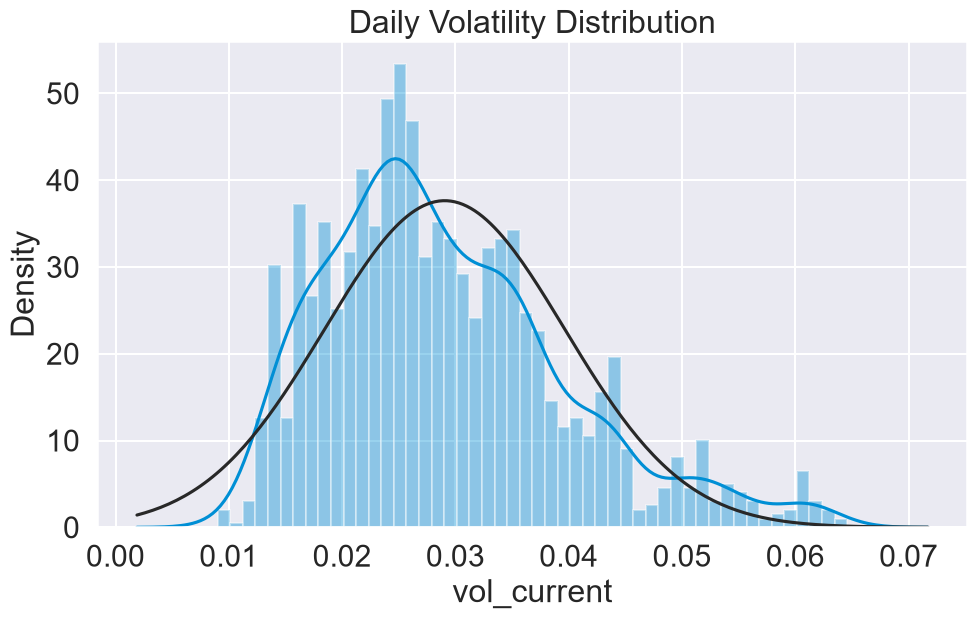

In [934]:
with sns.axes_style("darkgrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(df.vol_current, norm_hist=True, fit=stats.norm,
                bins=50, ax=ax)
    plt.title('Daily Volatility Distribution')
   # plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
    #            dpi=300, bbox_inches='tight')
    plt.show();

The distribution of daily realized volatility is lightly right skewed, with a small number of larger values spreaded thinly on the right.

A skewed right distribution would have smaller median compared to mean, and mode smaller than median (mode < median < mean).

### **Returns/Log Returns Stationarity Checking**



In [937]:
from statsmodels.tsa.stattools import adfuller

In [938]:
# LOG RETURNS
adfuller_results = adfuller(df.log_returns.dropna())

print(f'ADF Statistic: {adfuller_results[0]}')
print(f'p-value: {adfuller_results[1]}')
print('Critical Values:')
for key, value in adfuller_results[4].items():
    print(f'{key}: {value:.4f}')

ADF Statistic: -7.921695094951374
p-value: 3.7095031404572956e-12
Critical Values:
1%: -3.4341
5%: -2.8632
10%: -2.5676


In [939]:
# RETURNS
adfuller_results = adfuller(df.returns.dropna())

print(f'ADF Statistic: {adfuller_results[0]}')
print(f'p-value: {adfuller_results[1]}')
print('Critical Values:')
for key, value in adfuller_results[4].items():
    print(f'{key}: {value:.4f}')

ADF Statistic: -7.97457923797978
p-value: 2.7239488023224574e-12
Critical Values:
1%: -3.4341
5%: -2.8632
10%: -2.5676


Using a significant level alpha of 0.05, `p-value` for both Returns and Log Returns are significantly smaller than alpha, which means there's enough evidence to reject the Null Hypothesis. 

--> Returns and Log returns are both not dependent on time/trend

## **Train-Validation-Test Splits**

There're a total of 2500 usable datapoints in this dataset which covers a period of almost 7 years from October 2014 until today (end of August 2021). Since cryptocurrencies are not traded on a regulated exchange, the Bitcoin market is open 24/7, 1 year covers a whole 365 trading days instead of 252 days a year like with other stocks and commodities.

I would split the dataset into 3 parts as follows:
- the most recent 30 usable datapoints would be used for **Final Model Testing - approx. 1.2%**
- 1 full year (365 days) for **Validation and Model Tuning during training - approx. 14.7%**
- and the remaining for **Training - approx. 84.1%**

In [942]:
# PRE-DETERMINE DESIRED TEST & VALIDATION SIZES
test_size = 30
val_size = 365

# CONVERT TO INDICES
split_time_1 = len(df) - (val_size + test_size)
split_time_2 = len(df) - test_size

# GET CORRESPONDING DATETIME INDICES FOR EACH SET
train_idx = df.index[:split_time_1]
val_idx = df.index[split_time_1:split_time_2]
test_idx = df.index[split_time_2:]

In [943]:
print(f'TRAINING \tFrom: {train_idx[0]} \tto: {train_idx[-1]} \t{len(train_idx)} days')
print(f'VALIDATION \tFrom: {val_idx[0]} \tto: {val_idx[-1]} \t{len(val_idx)} days')
print(f'TEST \t\tFrom: {test_idx[0]} \tto: {test_idx[-1]} \t{len(test_idx)} days')

TRAINING 	From: 2021-01-31 00:00:00 	to: 2024-11-23 00:00:00 	1393 days
VALIDATION 	From: 2024-11-24 00:00:00 	to: 2025-11-23 00:00:00 	365 days
TEST 		From: 2025-11-24 00:00:00 	to: 2025-12-23 00:00:00 	30 days


The target here would be `vol_future` which represents the daily realized volatility of the next `n_future` days from today (average daily volatility from `t + n_future - INTERVAL_WINDOW` to time step `t + n_future`). 

For example, using an `n_future` value of 7 and an `INTERVAL_WINDOW` of 30, the value that I want to predict at time step `t` would be the average daily realized volatility from time step `t-22` to time step `t+7`.

In [945]:
# SPLIT FORWARD VOLATILITY INTO 3 PARTS 
# (this would be the target)
y_train = df.vol_future[train_idx]
y_val = df.vol_future[val_idx]
y_test = df.vol_future[test_idx]

In [946]:
# SPLIT CURRENT DAILY REALIZED VOLATILITY INTO 3 PARTS 
# (this would be the input for baseline, random walk, and NN models)
x_train = df.vol_current[train_idx]
x_val = df.vol_current[val_idx]
x_test = df.vol_current[test_idx]

In [948]:
# SPLIT RETURNS INTO 3 PARTS
# (this would be the input for GARCH models)
r_train = df.returns[train_idx]
r_val = df.returns[val_idx]
r_test = df.returns[test_idx]

In [949]:
# SPLIT LOG RETURNS INTO 3 PARTS
# (mostly for visualization)
lr_train = df.log_returns[train_idx]
lr_val = df.log_returns[val_idx]
lr_test = df.log_returns[test_idx]

In [950]:
y_train.describe()

count    1393.000000
mean        0.030817
std         0.010704
min         0.009005
25%         0.023190
50%         0.029297
75%         0.036665
max         0.064581
Name: vol_future, dtype: float64

In [951]:
x_train.describe()

count    1393.000000
mean        0.030922
std         0.010834
min         0.009005
25%         0.023190
50%         0.029297
75%         0.036838
max         0.064581
Name: vol_current, dtype: float64

## **Data Preprocessing**

### 1. Feature Normalization

As I am going to build various types of models based on different algorithms using different types of inputs, it would be better to normalize the volatilities to standardize the predictions generated by different models. After experimenting with different Scalers, I decided to use `MinMaxScaler` as it yielded best results overall.

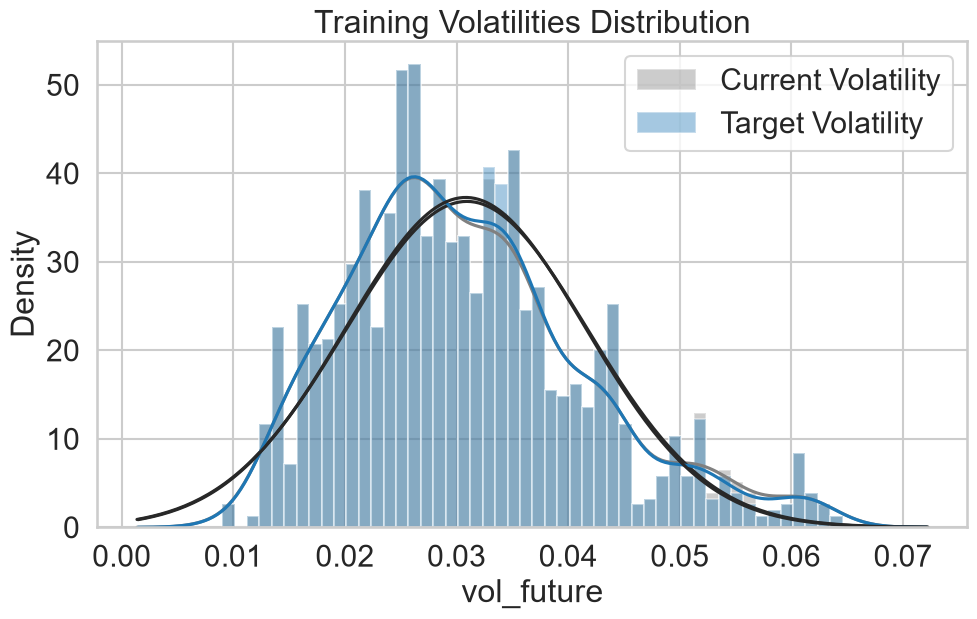

In [953]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(x_train, norm_hist=True, fit=stats.norm, 
                 color='gray', 
                 bins=50, ax=ax, label='Current Volatility')
    sns.distplot(y_train, norm_hist=True, fit=stats.norm,
                 color='tab:blue', 
                 bins=50, ax=ax, label='Target Volatility')
    plt.title('Training Volatilities Distribution')
    plt.legend()
    #plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

In [954]:
def transform_volatility_to_scaler(scaler, tf_series):
    '''
    Transform a series to a fitted scaler
    '''
    idx = tf_series.index
    output = pd.Series(scaler.transform(tf_series.values.reshape(-1,1))[:,0],
                       index=idx)
    return output

In [955]:
# INITIATE SCALER
scaler_vol = MinMaxScaler()

# FIT SCALER TO CURRENT VOLATILITY IN TRAINING SET
scaler_vol = scaler_vol.fit(x_train.values.reshape(-1,1))

In [956]:
# TRANSFORM TRAINING CURRENT & FUTURE VOLATILITIES 
x_train_scaled = transform_volatility_to_scaler(scaler_vol, x_train)
y_train_scaled = transform_volatility_to_scaler(scaler_vol, y_train)

# TRANSFORMING VALIDATION CURRENT & FUTURE VOLATILITIES
x_val_scaled = transform_volatility_to_scaler(scaler_vol, x_val)
y_val_scaled = transform_volatility_to_scaler(scaler_vol, y_val)

# TRANSFORMING TEST CURRENT & FUTURE VOLATILITIES
x_test_scaled = transform_volatility_to_scaler(scaler_vol, x_test)
y_test_scaled = transform_volatility_to_scaler(scaler_vol, y_test)

In [957]:
x_train.head(10)

2021-01-31    0.056789
2021-02-01    0.054349
2021-02-02    0.055249
2021-02-03    0.055952
2021-02-04    0.054850
2021-02-05    0.053142
2021-02-06    0.051950
2021-02-07    0.051557
2021-02-08    0.060580
2021-02-09    0.059923
Name: vol_current, dtype: float64

In [958]:
y_train.head(10)

2021-01-31    0.051557
2021-02-01    0.060580
2021-02-02    0.059923
2021-02-03    0.058604
2021-02-04    0.059166
2021-02-05    0.056477
2021-02-06    0.055763
2021-02-07    0.054912
2021-02-08    0.054893
2021-02-09    0.055066
Name: vol_future, dtype: float64

In [959]:
x_train_scaled.head(10)

2021-01-31    0.859800
2021-02-01    0.815889
2021-02-02    0.832087
2021-02-03    0.844728
2021-02-04    0.824906
2021-02-05    0.794168
2021-02-06    0.772726
2021-02-07    0.765648
2021-02-08    0.928005
2021-02-09    0.916187
dtype: float64

In [960]:
y_train_scaled.head(10)

2021-01-31    0.765648
2021-02-01    0.928005
2021-02-02    0.916187
2021-02-03    0.892460
2021-02-04    0.902561
2021-02-05    0.854177
2021-02-06    0.841341
2021-02-07    0.826021
2021-02-08    0.825687
2021-02-09    0.828801
dtype: float64

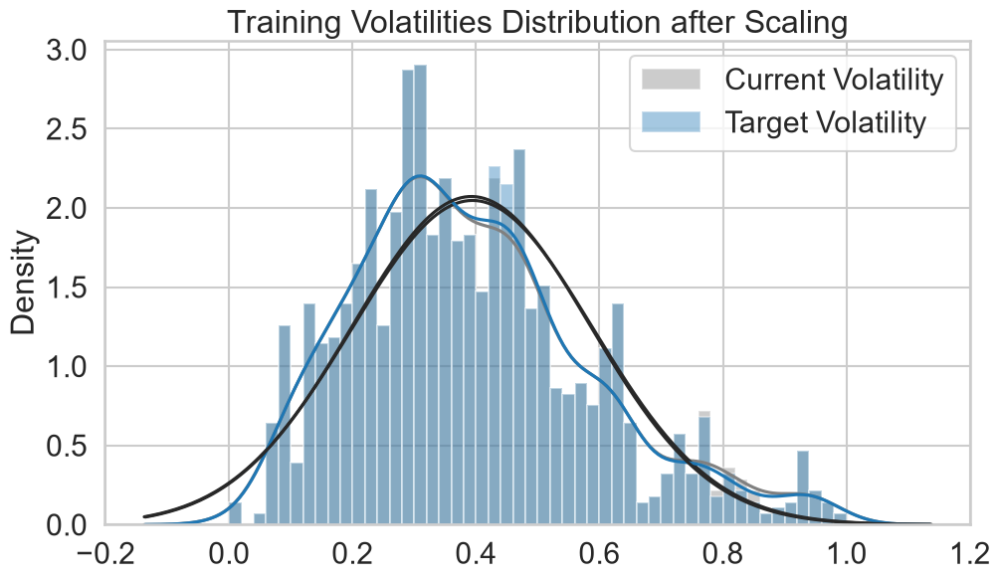

In [961]:
# PLOTTING VOLATILITIES AFTER SCALING
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10,6))
    sns.distplot(x_train_scaled, norm_hist=True, fit=stats.norm, 
                 color='gray', 
                 bins=50, ax=ax, label='Current Volatility')
    sns.distplot(y_train_scaled, norm_hist=True, fit=stats.norm,
                 color='tab:blue', 
                 bins=50, ax=ax, label='Target Volatility')
    plt.title('Training Volatilities Distribution after Scaling')
    plt.legend()
    #plt.savefig(os.path.join(directory_to_img, "vol_dist.png"), 
     #           dpi=300, bbox_inches='tight')
    plt.show();

### 2. Train-Validation-Test Visualization

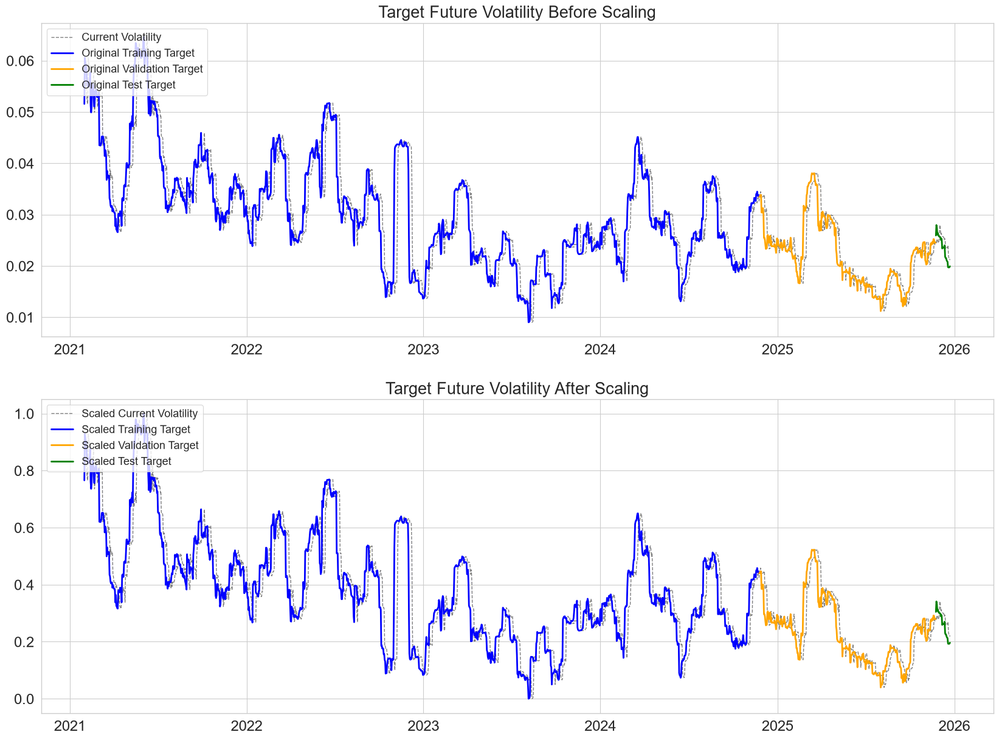

In [963]:
sns.set_context("paper", font_scale=2)

# VISUALIZE TRAIN/VALIDATION/TEST vol_future BEFORE & AFTER TRAINING
with sns.axes_style("whitegrid"):
    fig, (ax1, ax2) = plt.subplots(nrows=2, ncols=1, figsize=(18,14))

    ax1.plot(df.vol_current, lw=1, color='gray', ls='--',
                label='Current Volatility')
    ax1.plot(y_train, color='blue', label='Original Training Target', lw=2)
    ax1.plot(y_val, color='orange', label='Original Validation Target', lw=2)
    ax1.plot(y_test, color='green', label='Original Test Target', lw=2)

    ax1.title.set_text('Target Future Volatility Before Scaling')

    ax2.plot(transform_volatility_to_scaler(scaler_vol, df.vol_current), 
                lw=1, color='gray', ls='--',
                label='Scaled Current Volatility')
    ax2.plot(y_train_scaled, color='blue', label='Scaled Training Target', lw=2)
    ax2.plot(y_val_scaled, color='orange', label='Scaled Validation Target', lw=2)
    ax2.plot(y_test_scaled, color='green', label='Scaled Test Target', lw=2)

    ax2.title.set_text('Target Future Volatility After Scaling')

    ax1.legend(loc='upper left', prop={'size': 13}, frameon=True)
    ax2.legend(loc='upper left', prop={'size': 13}, frameon=True)
    #plt.savefig(os.path.join(directory_to_img, 'train_val_test_org_scled.png'), 
   #             dpi=300, bbox_inches='tight')
    plt.show();

One of the most obvious difference between the 2 plots is the y-axis. After scaling, volatilities fall in the range of [0,1] instead of [0, 0.12] as before.

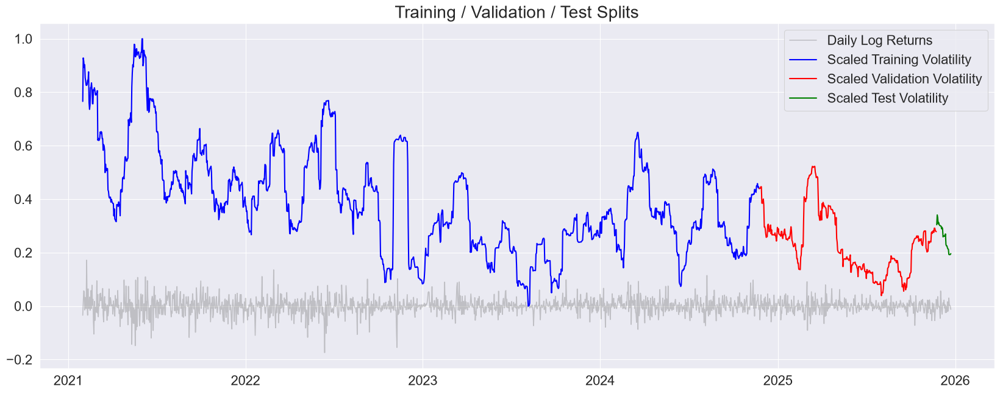

In [965]:
sns.set_context("paper", font_scale=1.8)
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(18,7))

    plt.plot(df.log_returns, color='gray', label='Daily Log Returns', alpha=0.4)

    plt.plot(y_train_scaled, color='blue', 
             label='Scaled Training Volatility', lw=1.5)
    plt.plot(y_val_scaled, color='red', 
             label='Scaled Validation Volatility', lw=1.5)
    plt.plot(y_test_scaled, color='green', 
             label='Scaled Test Volatility', lw=1.5)

    plt.plot()
    plt.title('Training / Validation / Test Splits', fontsize=20)
    plt.legend(frameon=True)
   # plt.savefig(os.path.join(directory_to_img, 'train_val_test.png'), 
   #             dpi=300, bbox_inches='tight')
    plt.show();

# MODELING

## 1. Performance Metrics

Usually with financial time series, if we just shift through the historic data trying different methods, parameters and timescales, it's almost certain to find to some strategy with in-sample profitability at some point. However the whole purpose of "forecasting" is to predict the future based on currently available information, and a model that performs best on training data might not be the best when it comes to out-of-sample generalization (or **overfitting**). Avoiding/Minimizing overfitting is even more important in the constantly evolving financial markets where the stake is high.

The 2 main metrics I'd be using are **RMSPE (Root Mean Squared Percentage Error)** and **RMSE (Root Mean Square Errors)** with RMSPE prioritized. Timescaling is very important in the calculation of volatility due to the level of freedom in frequency/interval window selection. Therefore I think RMSPE would help capture degree of errors compared to desired target values better than other metrics. Also RMSPE would punish large errors more than regular MAPE (Mean Absolute Percentage Error), which is what I want to do here.

RMSE and RMSPE would be tracked across different models' performance on validation set forecasting to indicate their abilities to generalize on out-of-sample data.

In [967]:
# DEFINE ROOT MEAN SQUARED PERCENTAGE ERROR FUNCTION
def RMSPE(y_true, y_pred):
    """
    Compute Root Mean Squared Percentage Error between 2 arrays
    """
    output = np.sqrt(np.mean(np.square((y_true - y_pred) / y_true)))
    return output

In [968]:
# DEFINE ROOT MEAN SQUARED ERROR FUNCTION
def RMSE(y_true, y_pred):
    """
    Compute Root Mean Squared Error between 2 arrays
    """
    output = np.sqrt(mse(y_true, y_pred))
    return output

In [969]:
# INITIATE A DATAFRAME FOR MODEL PERFORMANCE TRACKING & COMPARISON 
perf_df = pd.DataFrame(columns=['Model', 'Validation RMSPE', 'Validation RMSE'])

In [971]:
# A FUNCTION THAT LOGS MODEL NAME, RMSE AND RMPSE INTO perf_df
# FOR EASY COMPARISON LATER
def log_perf(y_true, y_pred, model_name):
    perf_df.loc[len(perf_df.index)] = [model_name, 
                                       RMSPE(y_true, y_pred), 
                                       RMSE(y_true, y_pred)]
    return perf_df

In [972]:
# PLOTTING MODEL PREDICTIONS VS. TARGET VALUES
def viz_model(y_true, y_pred, model_name):
    sns.set_context("paper", font_scale=1.7)
    plt.rcParams["axes.grid"] = False

    with sns.axes_style("whitegrid"):
        plt.figure(figsize=(18,7))
        plt.plot(x_val_scaled, color='gray',  ls=':',
                label=f"Scaled Current Daily Volatility")
        
        plt.plot(y_true, color='blue', lw=2, 
                label=f"Target Volatility")
        plt.plot(y_pred, color='orange', lw=2.5,
                label=f'Forecasted Volatility')
        
        plt.plot(lr_val, color='gray', alpha=0.4,
                 label='Daily Log Returns')

        plt.title(f'{model_name} \non Validation Data')
        plt.legend(loc='best', frameon=True)

## 2. Baseline Models

### 2.1. Mean Baseline

One of the essential characteristics of Volatility is it's **mean-revert** over the long term. Therfore my first baseline model his would be a very simple one that only outputs the average current realized volatility of the whole training set as predictions everything.

In [974]:
# CALCULATE THE MEAN OF SCALED TRAINING DATA
mean_train_vol = x_train_scaled.mean()
mean_train_vol

0.3943623245671191

In [975]:
# CREATE SERIES OF PREDICTIONS FOR BASELINE MODEL ON VALIDATION SET
baseline_preds = np.ones(len(val_idx)) * mean_train_vol
baseline_preds = pd.Series(baseline_preds, index=lr_val.index)

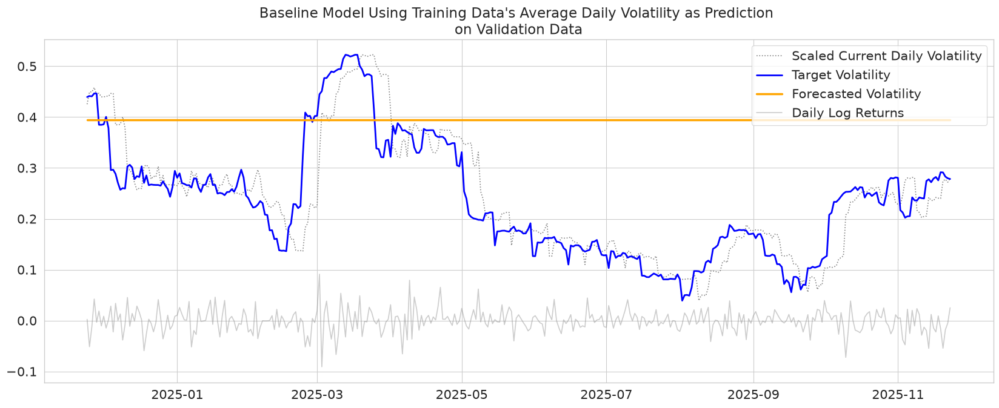

In [977]:
viz_model(y_val_scaled, baseline_preds, 
          f"Baseline Model Using Training Data's Average Daily Volatility as Prediction")
#plt.savefig(os.path.join(directory_to_img, 'baseline.jpg'), dpi=300, bbox_inches='tight')
plt.show();

In [978]:
log_perf(y_val_scaled, baseline_preds, 'Mean Baseline')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571


### 2.2. Random Walk Naive Forecasting

A commonly known fact about volatility is that it tends to be **autocorrelated**, and **clusters** in the short-term. This property can be used to implement a naive model that just "predicts" future volatility by using whatever the daily volatility was at the immediate previous time step.

In this case, I'll use the average daily volatility of the most recent `INTERVAL_WINDOW` as predictions for the next 7 days, which is essentially using `vol_current` at time step `t` and prediction for `vol_future` at time step `t`.

In [980]:
# USING THE PREVIOUS n_future DAY'S VOLATILITY
random_walk_preds = x_val_scaled

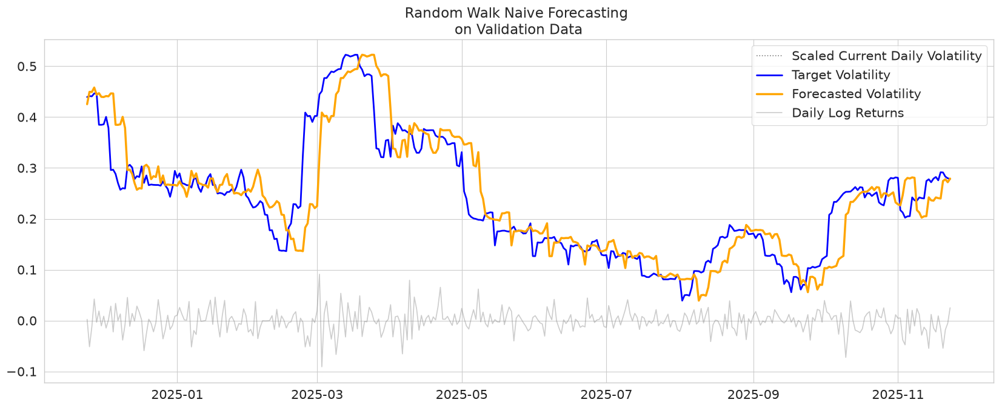

In [981]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, random_walk_preds, 'Random Walk Naive Forecasting')
#plt.savefig(os.path.join(directory_to_img, 'naive.jpg'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

In [982]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, random_walk_preds, 
         'Random Walk Naive Forecasting')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647


So the both error mertrics have gone down by a decent amount. Naive forecasting in time series is sometimes surprisingly difficult to outperform.

## 3. GARCH Models

(Reference: http://users.metu.edu.tr/ozancan/ARCHGARCHTutorial.html)

GARCH stands for **Generalized Autoregressive Conditional Heteroskedasticity**, which is an extension of the ARCH model (Autoregressive Conditional Heteroskedasticity). 

GARCH includes lag variance terms with lag residual errors from a mean process, and is the traditional econometric approach to volatility prediction of financial time series.

Mathematically, GARCH can be represented as follows:

\begin{align*}
\sigma_{t}^2 = \omega + \sum_{i}^{q}\alpha_{i}\epsilon_{t-i}^2 + \sum_{1}^{p}\beta_{i}\sigma_{t-i}^2
\end{align*}

in which $\sigma_{t}^2$ is variance at time step `t` and $\epsilon_{t-i}^2$ is the model residuals at time step `t-1`

GARCH(1,1) only contains first-order lagged terms and the mathematic equation for it is: 

\begin{align*}
\sigma^2_t = \omega + \alpha\epsilon^{2}_{(t-1)} + \beta\sigma^{2}_{(t-1)}
\end{align*}

where $\alpha$, $\beta$ and $\omega$ sum up to 1, and $\omega$ is the long term variance.


(Reference: **Positional Option Trading** - Euan Sinclair)

GARCH is generally regarded as an insightful improvement on naively assuming future volatility will be like the past, but also considered widely overrated as predictor by some experts in the field of volatility. GARCH models capture the essential characteristics of volatility: volatility tomorrow will be close to what it is today (**clustering**), and volatility in the long term will probably **mean revert** (meaning it'd be close to whatever the historical long-term average has been).

### 3.1. Basic GARCH

In [986]:
# VISUALIZE AUTOCORRELATION OF SQUARED RETURNS
plot_acf(r_train**2, 
          title=f'{tckr.upper()} Returns Autocorrelation\n(Training Set)');

In [987]:
# VISUALIZE PARTIAL AUTOCORRELATION OF SQUARED RETURNS
plot_pacf(r_train**2, 
          title=f'{tckr.upper()} Returns Partial AutoCorrelation\n(Training Set)');

The autocorrelation plots seem to indicate that there's only significant correlation up to the 7th lags, and the ones following don't seem to be too significant.

GARCH models are trained on percent returns. (One of the reasons I decided to normalize the volatilities across the board is because I am still not 100% sure which timescale GARCH conditional volatility is calculated in (likely daily), and still haven't figured out why the outputs here seem to be on a totally different scale compared to the volatilities previously calculated. Once I scale them, they match up much more nicely).

In [991]:
from arch import arch_model

In [992]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

gm_1 = arch_model(r_train, p=7, q=7)
result_1 = gm_1.fit(disp='off')
print()
print(result_1.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3489.99
Distribution:                  Normal   AIC:                           7011.97
Method:            Maximum Likelihood   BIC:                           7095.80
                                        No. Observations:                 1393
Date:                Fri, Nov 13 2026   Df Residuals:                     1392
Time:                        19:06:00   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
---------------------------------------------------------------------------
mu             0.1303  7.284e-02      1.789  7.355e-02 [-1.2

Using a significance level of 0.05, none of the coefficients seems to be statistically significant (because their p-values `P > |t|` are all greater than 0.05). Therefore, I'll reduce the values of `p` and `q` to 1 to see if that helps.

In [994]:
gm_1 = arch_model(r_train, vol='GARCH', p=1, q=1)
result_1 = gm_1.fit(disp='off')
print()
print(result_1.summary())


                     Constant Mean - GARCH Model Results                      
Dep. Variable:                returns   R-squared:                       0.000
Mean Model:             Constant Mean   Adj. R-squared:                  0.000
Vol Model:                      GARCH   Log-Likelihood:               -3530.47
Distribution:                  Normal   AIC:                           7068.95
Method:            Maximum Likelihood   BIC:                           7089.90
                                        No. Observations:                 1393
Date:                Fri, Nov 13 2026   Df Residuals:                     1392
Time:                        19:06:01   Df Model:                            1
                                Mean Model                                
                 coef    std err          t      P>|t|    95.0% Conf. Int.
--------------------------------------------------------------------------
mu             0.1631  7.686e-02      2.122  3.382e-02 [1.247e-

All coefficients look statistically significant now.

After being fitted to the training data (percent returns), the GARCH model forecast contains an estimated conditional volatility attribute for the training portion of the time series. I am going to fit - transform the scaler to the training data's conditional volatility arrays, and then plot it out to compare it with the realized volatility calculated above (also scaled) `x_train_scaled`.

In [996]:
def scale_tf_cond_vol(model_result):
    '''
    Scale & Transform Conditional Volatility 
    Estimated by GARCH Models
    '''
    # OBTAIN ESTIMATED CONDITIONAL VOLATILITY FROM MODEL RESULT
    cond_vol = model_result.conditional_volatility

    # INITIATE SCALER
    scaler = MinMaxScaler()

    # FIT SCALER TO MODEL'S ESTIMATED CONDITIONAL VOLATILITY
    scaler = scaler.fit(cond_vol.values.reshape(-1,1))

    scaled_cond_vol = transform_volatility_to_scaler(scaler, cond_vol)
    return scaler, scaled_cond_vol

In [997]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_garch, scaled_cond_vol = scale_tf_cond_vol(result_1)

In [998]:
# VISUALIZE MODEL'S ESTIMATED CONDITIONAL VOLATILITY 
# WITH SCALED vol_current CALCULATED ABOVE
def viz_cond_vol(cond_vol_series, model_name):
    with sns.axes_style("darkgrid"):
        fig, ax = plt.subplots(figsize=(18,7))

        ax.plot(x_train_scaled, color='blue', lw=2,
                label=f'Scaled {INTERVAL_WINDOW}-Day Interval Daily Realized Volatility')
        ax.plot(cond_vol_series, color='orange', lw=2,
                label=f'Scaled {model_name} Estimated Conditional Volatility')
        ax.set_title('Training Set')
        plt.legend()
        plt.show();

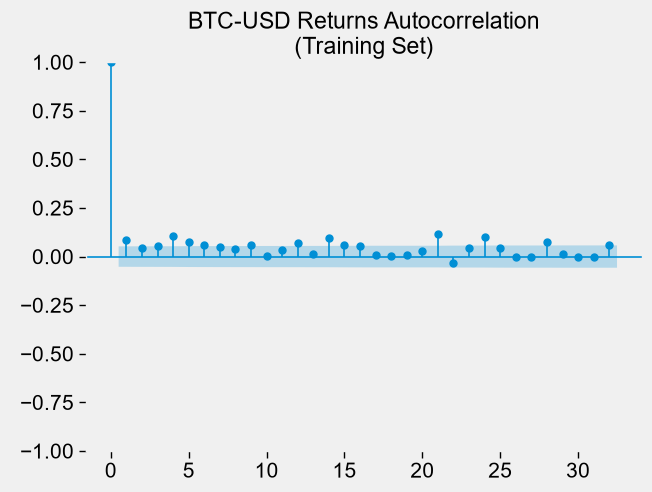

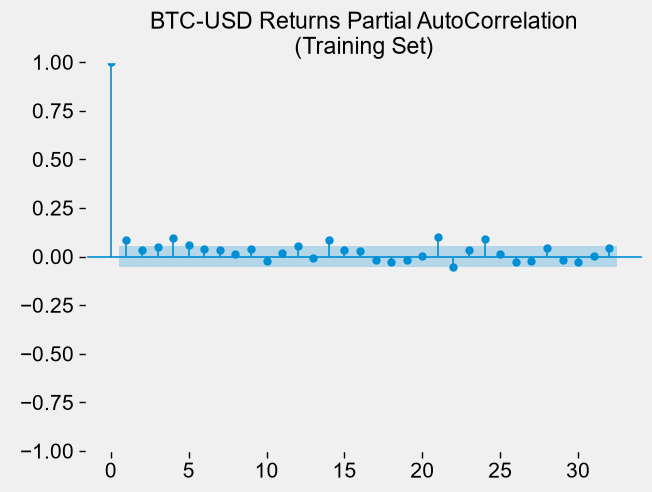

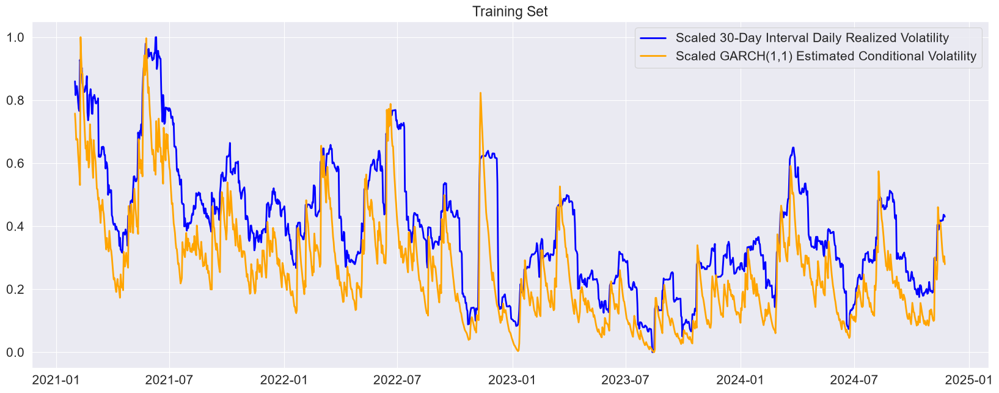

In [999]:
viz_cond_vol(scaled_cond_vol, 'GARCH(1,1)')

#### 3.1.1. Analytical-based Forecasting

(Source: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html)

I am implementing rolling one-step forecasting here by refitting the model to ALL the datapoints available up to a certain time step before generating prediction for the next `n_future` days. For example, to make prediction on `vol_future` at time step `t`, I would fit the model to all the `returns` available up to time step `t` and then obtain the average forecasted volatility for a horizon of `n_future = 7`.

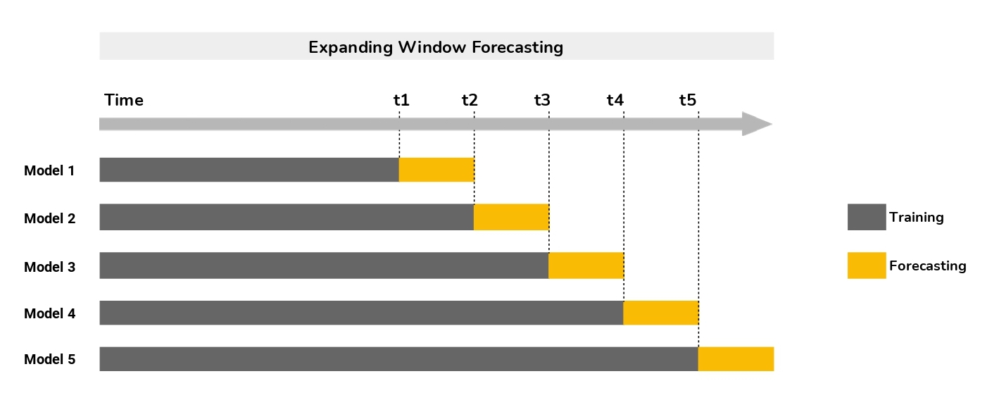

The volatility forecasts from the GARCH models using percent returns as input are on a totally different scale compared to the volatilities calculated from log returns. Therefore I am going to normalize the forecasted volatility based on the model's `conditional_volatility` output from the training data, and only comparing the scaled versions of volatilities on the Validation set.

In [1001]:
# ONE STEP EXPANDING WINDOW FORECAST
# INITIALIZING rolling_forecast
rolling_forecasts = []
idx = df.index

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx]
    
    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, vol='GARCH', p=1, q=1,
                       dist='normal')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False).variance.values
    # GET THE SQRT OF AVERAGE n_future DAYS VARIANCE
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

gm_1_preds = pd.Series(rolling_forecasts, index=val_idx)

In [1002]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
gm_1_preds_scaled = transform_volatility_to_scaler(scaler_garch, gm_1_preds)

In [1003]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, gm_1_preds_scaled, 
          'Analytical Forecasting GARCH(1,1) Constant Mean Normal Distribution')

So 7-day horizon forecasting into the future is still lagging behind compared to target values. Similar to the training volatilities comparison above, GARCH's forecasted volatility appears to be lower side (after normalization).

In [1006]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, gm_1_preds_scaled, 
         'GARCH(1,1), Constant Mean, Normal Dist')

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647
2,"GARCH(1,1), Constant Mean, Normal Dist",0.499564,0.111557


Next, I would inspect the estimated residuals from this first GARCH model.

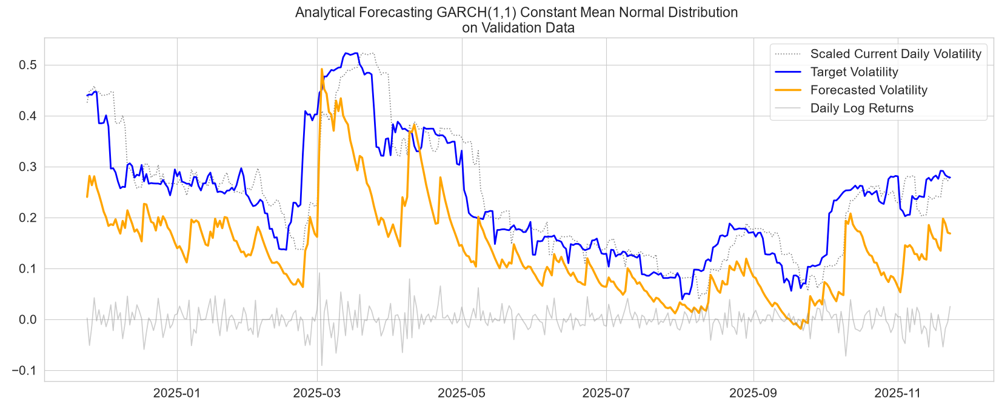

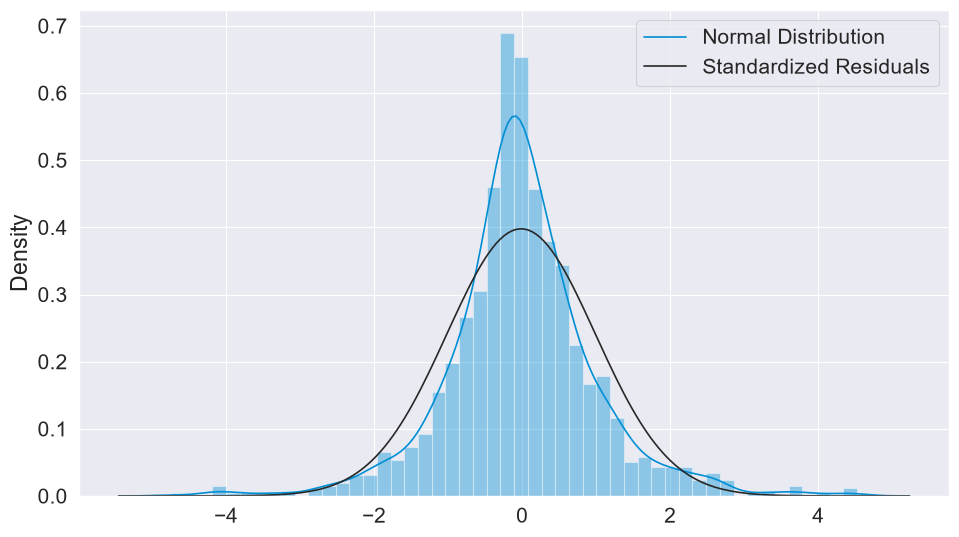

In [1008]:
# INSPECTING THE RESIDUALS
gm_resid = result_1.resid
gm_std = result_1.conditional_volatility

# STANDARDIZING RESIDUALS
gm_std_resid = gm_resid / gm_std

# VISUALIZING STANDARDIZED RESIDUALS VS. A NORMAL DISTRIBUTION
with sns.axes_style("darkgrid"):
    plt.figure(figsize=(10,6))
    sns.distplot(gm_std_resid, norm_hist=True, fit=stats.norm, bins=50)
    plt.legend(('Normal Distribution', 'Standardized Residuals'))
    plt.show();

(Reference: https://goldinlocks.github.io/ARCH_GARCH-Volatility-Forecasting/)

By default, basic GARCH is based on some assumptions that the residuals and the mean return are both normally distributed. However, more often than not, financial time series data does not follow a normal distribution, and it's more likely to observe extreme positive and negative values that are far away from the mean. 

Fortunately, there're certain parameters that can be specified in the `arch_model` library to make it more representative of real financial data:
- `'dist'` can be set to `t` for Student's T or `skewt` for skewed Student's T distribution (Student's T distribution is also symmetric and bell-shaped like normal distribution; however it has higher peak and fatter tails allowing more values lying further away from the mean).

Looking at the plot above of the standardized residuals, I think I can try skewed Student's T for the next fit.



### 3.2. GARCH Model with Asymmetric Shocks Responses

The basic GARCH model assumes positive and negative news have similar impact on volatility. However, in reality the market tends to "*take the stairs up and the elevator down*". In other words, the impact is usually asymmetric, and negative impacts tends to affect the volatility more than positive ones.

There's another member in the GARCH family that accounts for assymmetry of shocks reponses called **GJR-GARCH** (short for **Glosten-Jagannathan-Runkle GARCH**).

Additional inputs can be used to construct other models. In this case, by setting `o` to 1, which means the model would include one lag of an asymmetric shock which transforms a GARCH model into a GJR-GARCH model with variance dynamics.

In [1011]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

gjr_gm = arch_model(r_train, p=1, q=1, o=1, 
                    vol='GARCH', dist='skewt')
result_2 = gjr_gm.fit(disp='off')
print(result_2.summary())

                         Constant Mean - GJR-GARCH Model Results                         
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                             GJR-GARCH   Log-Likelihood:               -3417.38
Distribution:      Standardized Skew Student's t   AIC:                           6848.77
Method:                       Maximum Likelihood   BIC:                           6885.44
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:06:17   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
--------------------------------------------

Log-likelihood has increased quite a bit. Let's see how the conditional volatility looks.

In [1013]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_gjr, scaled_gjr_cond_vol = scale_tf_cond_vol(result_2)

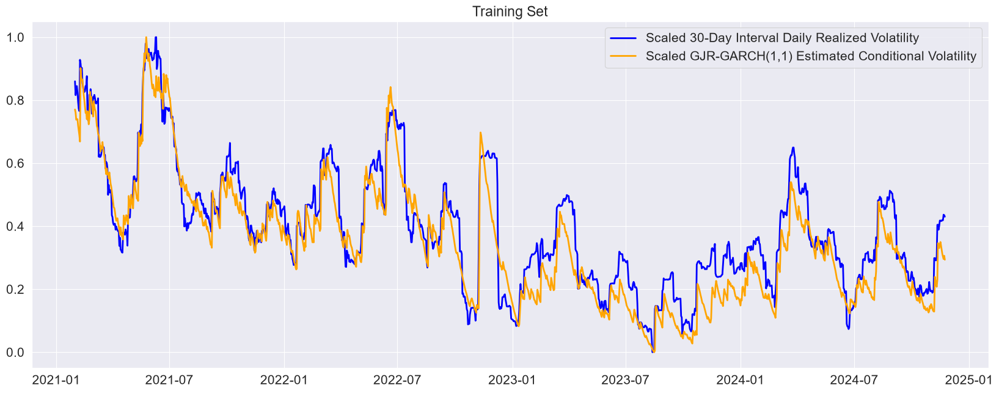

In [1068]:
viz_cond_vol(scaled_gjr_cond_vol, 'GJR-GARCH(1,1)')

In [1069]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, q=1, o=1, 
                       vol='GARCH', dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False).variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

gjr_1_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1071]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
gjr_1_preds_scaled = transform_volatility_to_scaler(scaler_gjr, gjr_1_preds)

In [1072]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, gjr_1_preds_scaled, 
          "Analytical Forecasting GJR-GARCH(1,1,1) with Constant Mean Skewed Student's T Distribution")

In [1073]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, gjr_1_preds_scaled, 
         "Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647
2,"GARCH(1,1), Constant Mean, Normal Dist",0.499564,0.111557
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.324690,0.066088


Compared to GARCH(1,1) with Normal Distribution setting, GJR-GARCH with Skewed Student's T forecasts have moved up quite a bit and shortened the gap between target values and model's predictions. This is also reflected in an improvement in both Validation RMSPE and RMSE.

Unfortunately I still haven't been able to get close to Naive Forecasting.

### 3.3. TARCH

(Reference: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_modeling.html#Specifying-Common-Models)

There's another member in the GARCH family called **TARCH**, which is short for **Threshold Autoregressive Conditional Heteroskedasticity** (and also known as **ZARCH**). TARCH models the volatility using absolute values (instead of squares). This model is specified using `power=1.0` since the default power, `2.0`, corresponds to variance processes that evolve in squares. In addition, asymmetric impact is also incorporated into the GARCH framework by using a dummy variable

The volatility process in a TARCH(1,1) model is given by:

\begin{align*}
\sigma_{t} = \omega + \alpha|\epsilon_{t-1}| + \gamma|\epsilon_{t-1}|I_{[\epsilon_{t-1}<0]} + \beta\sigma_{t-1}
\end{align*}

In [1076]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

t_gm = arch_model(r_train, p=1, o=1, q=1, power=1.0,
                  dist='skewt')
result_3 = t_gm.fit(disp='off')
print(result_3.summary())

                        Constant Mean - TARCH/ZARCH Model Results                        
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                           TARCH/ZARCH   Log-Likelihood:               -3416.96
Distribution:      Standardized Skew Student's t   AIC:                           6847.92
Method:                       Maximum Likelihood   BIC:                           6884.60
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:08:28   Df Model:                            1
                               Mean Model                               
                 coef    std err          t      P>|t|  95.0% Conf. Int.
--------------------------------------------

Log-likelihood and AIC/BIC are quite similar to the GJR-GARCH model. Next I'll inspect the estimated conditional volatility compared to the scaled `vol_current`.

In [1078]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_tarch, scaled_tarch_cond_vol = scale_tf_cond_vol(result_3)

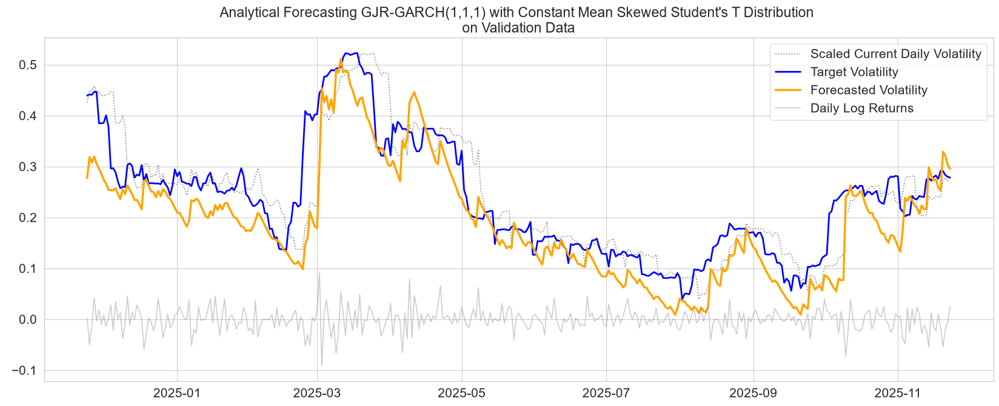

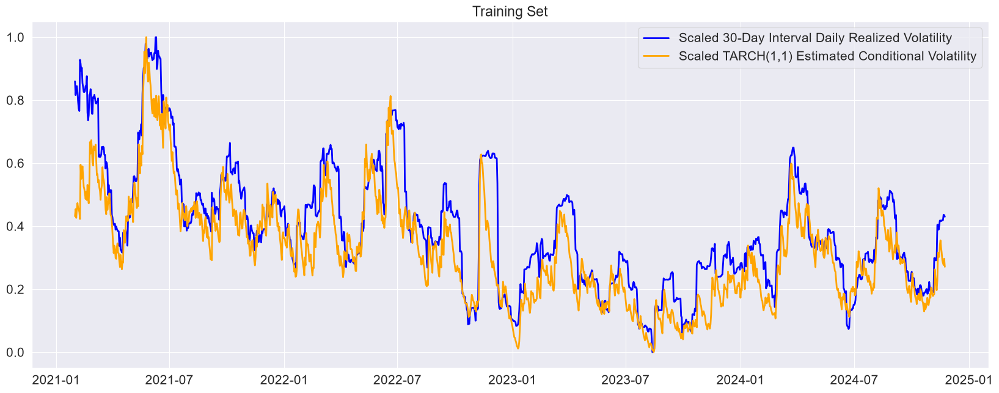

In [1079]:
viz_cond_vol(scaled_tarch_cond_vol, 'TARCH(1,1)')

#### 3.3.1. Bootstrap-based Forecasting for TARCH(1,1)

(Reference: https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html#TARCH)

TARCH models do not have closed-form (analytical) forecasts for horizons larger than 1, and so simulation or bootstrapping is required.

Bootstrap-based forecasts are nearly identical to simulation-based forecasts except that the values used to simulate the process are computed from historical data rather than using the assumed distribution of the residuals. Forecasts produced using this method also return an `ARCHModelForecastSimulation` containing information about the simulated paths.

In [1081]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, o=1, q=1, power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING BOOTSTRAP METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='bootstrap').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_bs_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

TARCH one-step forecasting seems to produce some convergence issues. I still want to look at the results though.

In [1083]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_bs_preds_scaled = transform_volatility_to_scaler(scaler_tarch, t_bs_preds)

In [1084]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_bs_preds_scaled, 
          "Bootstrap TARCH(1,1) Constant Mean Skewed Student's T Distribution")

The forecasted volatility does seem to catch up with the target better than all other models did. This is promising...

In [1086]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_bs_preds_scaled, 
         "Bootstrap TARCH(1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647
2,"GARCH(1,1), Constant Mean, Normal Dist",0.499564,0.111557
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.324690,0.066088
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.246982,0.062037


Bootstrap TARCH(1,1) has managed to achieve a lower Validation RMSPE than Naive Forecasting!!! Even RMSE is only a bit higher, but so far this has been the best model among all GARCH family members that I've found. 

(I'm not liking the ConvergenceWarning messages that TARCH produces during training though...)

#### 3.3.2. Simulation-based Forecasting for TARCH(1,1)



In [1089]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=1, o=1, q=1, power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING SIMULATION METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='simulation').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_sm_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1090]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_sm_preds_scaled = transform_volatility_to_scaler(scaler_tarch, t_sm_preds)

In [1091]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_sm_preds_scaled, 
          "Simulation TARCH(1,1) Constant Mean Skewed Student's T Distribution")

In [1092]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_sm_preds_scaled, 
         "Simulation TARCH(1,1), Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647
2,"GARCH(1,1), Constant Mean, Normal Dist",0.499564,0.111557
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.324690,0.066088
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.246982,0.062037
5,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.246064,0.061661


Among the 2 forecasting methods, bootstrap seems to perform better on TARCH(1,1). It's probably because bootstrap uses historical data in to compute rather than using the assumed distribution of the residuals.

#### 3.3.3. Hyperparameter Tuning for TARCH

Next, I'll create a range of values for p, q and o from 0 to 3 (inclusive), and then record each's model's performance on unseen data using RMSPE. Since `p` cannot take a value of `0`, I'll eliminate that from the list of permutations. 

In [1095]:
import itertools

In [1096]:

# 1. FIX THE RANGE: range(4) generates [0, 1, 2, 3] for inclusive bounds
pqo_combinations = [p for p in itertools.product(range(4), repeat=3)]
# Eliminate combinations where p == 0
pqo_s = list(filter(lambda x: x[0] != 0, pqo_combinations))

# Performance storage lists
LLH_s = []
bic_s = []
rmspe_s = []

# Define your complete timeline context
# We use the full available data series for rolling updates without refitting
full_series = df.returns.dropna()
first_val_idx = val_idx[0]

for p, q, o in pqo_s:
        np.random.seed(seed)
    
        # A. In-sample fitting on baseline training data
        t_gm_pqo = arch_model(r_train, p=p, q=q, o=o, power=1.0, dist='skewt')
        t_gm_pqo_fit = t_gm_pqo.fit(disp='off')
        
        # B. OPTIMIZATION: Fit model ONCE on the full dataset but specify the split
        # This allows the backend to generate rolling forecasts instantly without a Python loop
        rolling_model = arch_model(full_series, p=p, q=q, o=o, power=1.0, dist='skewt')
        
        # By passing update_freq=0, parameters are held fixed at r_train estimates, 
        # or you can set a higher number to update them periodically instead of every step
        rolling_fit = rolling_model.fit(last_obs=first_val_idx, disp='off')
        
        # C. Instant vectorized out-of-sample forecasting (No inner loop!)
        # The 'start' parameter tells it exactly where your validation set begins
        forecasts = rolling_fit.forecast(horizon=n_future, align='origin', method='bootstrap')
        
        # Extract variance and calculate root mean variance
        # Mean variance across horizons handles your 'n_future' averaging step natively
        rolling_vars = forecasts.variance.loc[val_idx]
        mean_vars = rolling_vars.mean(axis=1)
        rolling_forecasts = np.sqrt(mean_vars)
       
        # D. Unified scaling logic
        sclr = MinMaxScaler()
        cond_vol_arr = t_gm_pqo_fit.conditional_volatility.values.reshape(-1, 1)
        sclr.fit(cond_vol_arr)
        
        y_preds = pd.Series(rolling_forecasts, index=val_idx)
        y_preds_scaled = transform_volatility_to_scaler(sclr, y_preds)
        
        # E. Metric Recording
        LLH_s.append(t_gm_pqo_fit.loglikelihood)
        bic_s.append(t_gm_pqo_fit.bic)
        rmspe_s.append(RMSPE(y_val_scaled, y_preds_scaled))
        

In [1097]:
# GET THE VALUES OF p/q/o THAT YIELDS LOWEST VALIDATION RMSPE
print(f'Lowest RMSPE is {np.min(rmspe_s)} using TARCH{pqo_s[np.argmin(rmspe_s)]}')

Lowest RMSPE is 0.2056400911784825 using TARCH(3, 2, 0)


In [1098]:
best_pqo = pqo_s[np.argmin(rmspe_s)]

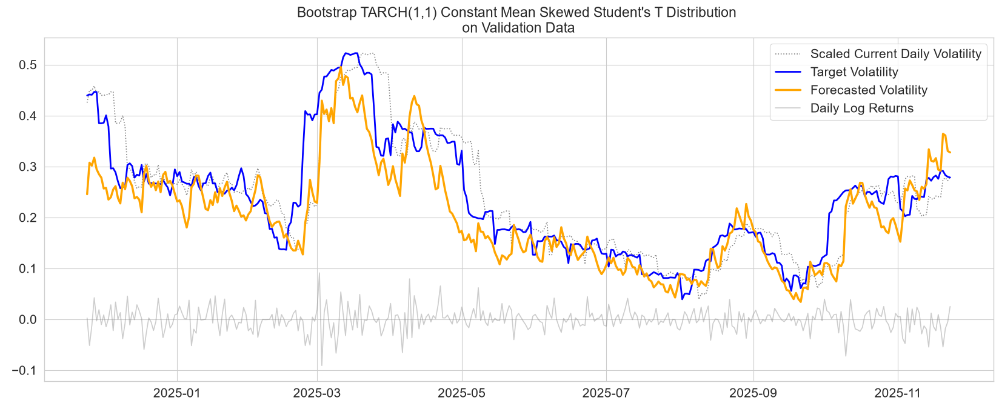

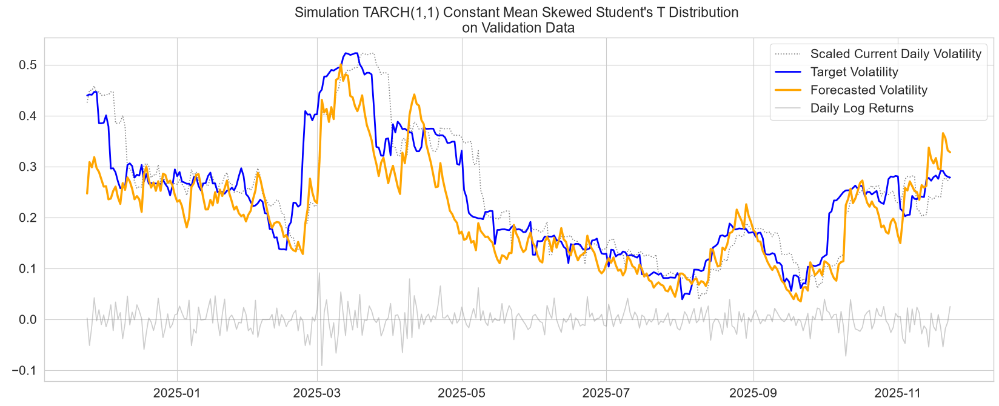

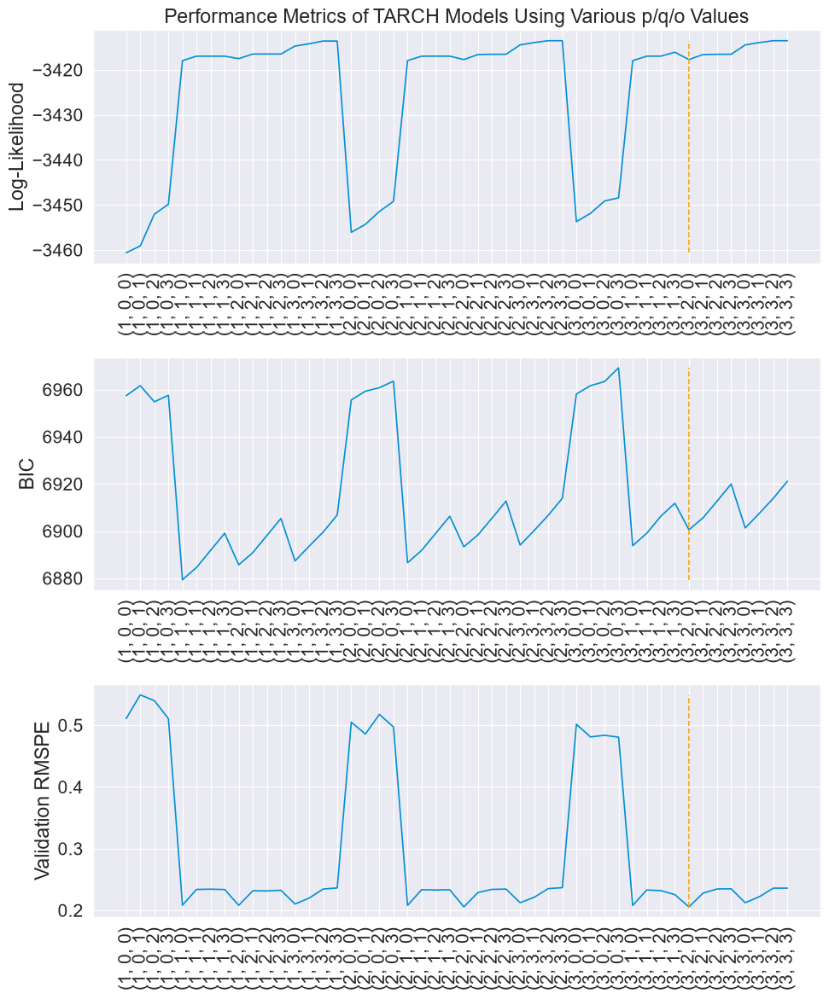

In [1099]:
with sns.axes_style("darkgrid"):
    fig, (ax1, ax2, ax3) = plt.subplots(nrows=3, ncols=1, figsize=(10,12))
    xlabels = [str(v) for v in pqo_s]

    ax1.plot(xlabels, LLH_s)
    ax1.set_xticklabels(xlabels, rotation=90)
    ax1.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(LLH_s), ymax=np.max(LLH_s))
    ax1.set_ylabel('Log-Likelihood')

    ax2.plot(xlabels, bic_s)
    ax2.set_xticklabels(xlabels, rotation=90)
    ax2.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(bic_s), ymax=np.max(bic_s))
    ax2.set_ylabel('BIC')

    ax3.plot(xlabels, rmspe_s)
    ax3.set_xticklabels(xlabels, rotation=90)
    ax3.vlines(x=str(best_pqo), 
               ls='--', color='orange',
               ymin=np.min(rmspe_s), ymax=np.max(rmspe_s))
    ax3.set_ylabel('Validation RMSPE')

    ax1.set_title('Performance Metrics of TARCH Models Using Various p/q/o Values')
    plt.tight_layout()
    plt.show();    

So it seems (2,2,0) yields lowest RMPSE on validation set among all the variants I've tried. I'm going to create another TARCH model with this paramaters to see how the results would look like.

### 3.4. Final GARCH Model - TARCH(2,2)

I will train another sets of TARCH model using the p/q/o values found from tuning above.

In [1101]:
# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

t_120 = arch_model(r_train, p=best_pqo[0], q=best_pqo[1], o=best_pqo[2], power=1.0,
                  dist='skewt')
result_4 = t_120.fit(disp='off')
print(result_4.summary())

                          Constant Mean - AVGARCH Model Results                          
Dep. Variable:                           returns   R-squared:                       0.000
Mean Model:                        Constant Mean   Adj. R-squared:                  0.000
Vol Model:                               AVGARCH   Log-Likelihood:               -3417.72
Distribution:      Standardized Skew Student's t   AIC:                           6853.43
Method:                       Maximum Likelihood   BIC:                           6900.59
                                                   No. Observations:                 1393
Date:                           Fri, Nov 13 2026   Df Residuals:                     1392
Time:                                   19:11:26   Df Model:                            1
                                 Mean Model                                
                 coef    std err          t      P>|t|     95.0% Conf. Int.
--------------------------------------

In [1102]:
# GET VOLATILITY SCALER & SCALED CONDITIONAL VOLATILITY FROM MODEL RESULT
scaler_tarch_120, scaled_tarch_120_cond_vol = scale_tf_cond_vol(result_4)

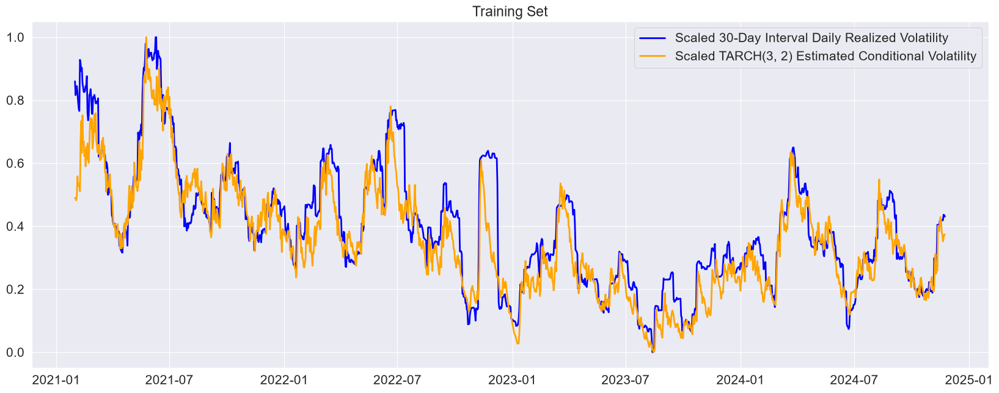

In [1103]:
viz_cond_vol(scaled_tarch_120_cond_vol, f'TARCH{best_pqo[:2]}')

In [1104]:
# ROLLING WINDOW FORECAST
# INITIALIZING rolling_forecasts VALUES LIST
rolling_forecasts = []

# ITERATE OVER EACH TIME STEP IN THE VALIDATION SET
for i in range(len(val_idx)):
    # GET THE DATA AT ALL PREVIOUS TIME STEPS
    idx = val_idx[i]
    train = df.returns[:idx].dropna()

    # TRAIN MODEL USING ALL PREVIOUS TIME STEPS' DATA
    model = arch_model(train, p=best_pqo[0], q=best_pqo[1], o=best_pqo[2], power=1.0,
                       dist='skewt')
    model_fit = model.fit(disp='off')

    # MAKE PREDICTION n_future DAYS OUT
    # USING BOOTSTRAP METHOD
    vaR = model_fit.forecast(horizon=n_future, 
                             reindex=False,
                             method='bootstrap').variance.values
    pred = np.sqrt(np.mean(vaR))

    # APPEND TO rolling_forecasts LIST
    rolling_forecasts.append(pred)

t_bs_120_preds = pd.DataFrame(rolling_forecasts, index=val_idx)

In [1105]:
# TRANSFORM PREDICTIONS USING FITTED SCALER
t_120_preds_scaled = transform_volatility_to_scaler(scaler_tarch_120, t_bs_120_preds)

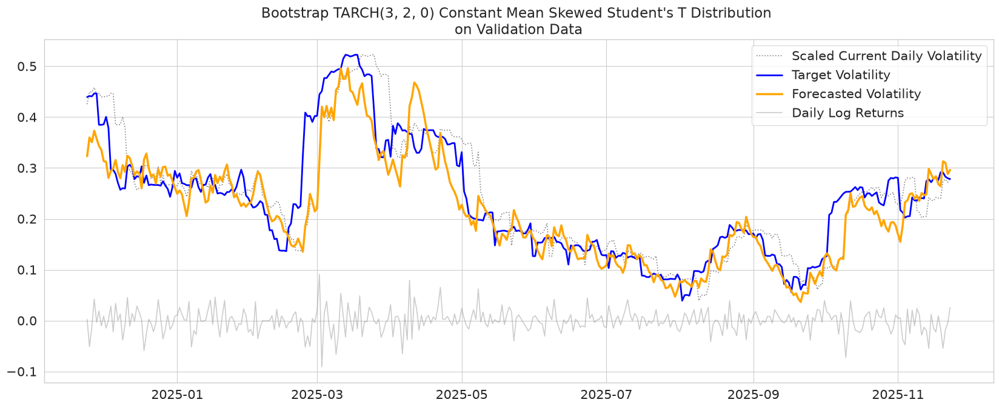

In [1106]:
# PLOTTING PREDICTIONS VS. TARGET VALUES ON VALIDATION SET
viz_model(y_val_scaled, t_120_preds_scaled, 
          f"Bootstrap TARCH{best_pqo} Constant Mean Skewed Student's T Distribution")
#plt.savefig(os.path.join(directory_to_img, 'best_tarch_preds.png'), 
 #           dpi=300, bbox_inches='tight')
plt.show();

In [1107]:
# APPEND METRICS OUTPUTS TO perf_df DATAFRAME
log_perf(y_val_scaled, t_120_preds_scaled, 
         f"Bootstrap TARCH{best_pqo}, Constant Mean, Skewt Dist")

,Model,Validation RMSPE,Validation RMSE
0,Mean Baseline,1.773657,0.194571
1,Random Walk Naive Forecasting,0.268156,0.055647
2,"GARCH(1,1), Constant Mean, Normal Dist",0.499564,0.111557
3,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.324690,0.066088
4,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.246982,0.062037
5,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.246064,0.061661
6,"Bootstrap TARCH(3, 2, 0), Constant Mean, Skewt Dist",0.207061,0.051223


## 4. Neural Networks

While GARCH remains the gold standard for volatility prediction within traditional financial institutions, there has been an increasing numbers of professionals and researchers turning to Machine Learning, especially Neural Networks, to gain insights into the financial markets in recent years.

(Reference: **Positional Option Trading** - Euan Sinclair)

Traders' theory of the market being inherently efficient (Efficient Market Hypothesis or EHM) states that share prices reflects all information and consistently outperforming the overall market is impossible. The more efficient a market is, the more random and unpredictable the returns will be, and thus **a perfectly efficient market will be completely unpredictable**. 

There are other arguments against EMH, and ones of the most prominent one is based on **Behavioral Finance**: compared to the human history of 200,000 years, the market has not been around for that long. For example, equity options have only been traded in liquid, transparent market since the CBOE opened in 1973; and the average lifetime of an S&P500 company is approx. 20 years. It means that some psychological tendencies of human beings have 200,000 years of evidence behind them, and that a lot of the movements of the markets that were driven by participants' behaviors will likely repeat itself at a later point. Therefore the market system cannot be totally random, it must have some patterns. Those patterns are extremely difficult to exploit due to the multitude of factors that interact and drive the market. 

It'd be interesting to see how Neural Networks perform compared to the traditional GARCH models.

In [1109]:
#!pip install tensorflow

In [1110]:
import tensorflow as tf
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras import backend as K
from decimal import Decimal

For Neural Networks, instead of feeding all available datapoints into the network at once, I will use a **sliding lookback window** to extract uniform input arrays and target outputs. I will just using a stride value of 1 to make sure I get all the inputs and output combinations available since 2500 datapoints is not really a whole lot to spare. 

This is a demonstration of sliding window:

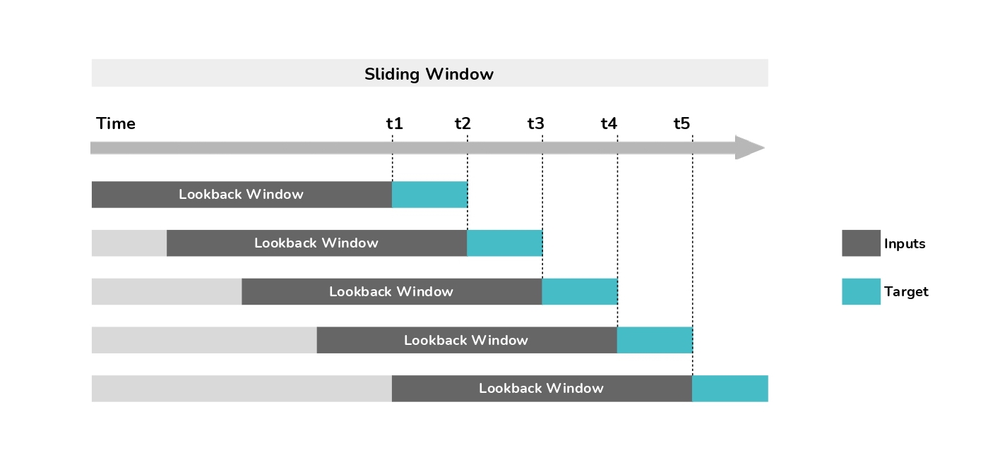

In [1112]:
# CONVERT AN SERIES TO MATRIX DATASET
def windowed_dataset(x_series, y_series, lookback_window):
    dataX, dataY = [], []
    for i in range((lookback_window-1), len(x_series)):
        start_idx = x_series.index[i-lookback_window+1]
        end_idx = x_series.index[i]
        a = x_series[start_idx:end_idx].values
        dataX.append(a)
        dataY.append(y_series[end_idx])

    return np.array(dataX), np.array(dataY)

In [1113]:
def rmspe(y_true, y_pred):
    '''
    Compute Root Mean Square Percentage Error between two arrays
    that can be used as metrics for NN during training
    '''
    loss = K.sqrt(K.mean(K.square((y_true - y_pred) / y_true)))

    return loss

To generate predictions using Neural Networks, I will use the same sliding window concept again:

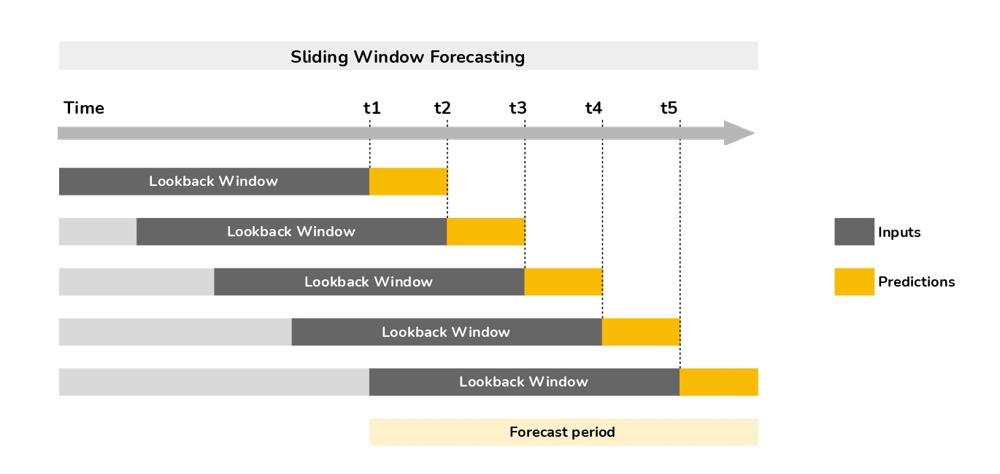

This means that to generate future predictions for a time step `t`, I will need to traverse back in time and collect the last `n_past` datapoints (from time step `t - n_past + 1` to `t` inclusively). That's why the shape of the inputs into these Neural Networks need to be **`[batch_size, n_past, 1]`**.

In [1115]:
def forecast(model, range_idx, n_past):
    start_idx = range_idx[0] - timedelta(n_past - 1)
    end_idx = range_idx[-1]
    mat_X, _ = windowed_dataset(df.vol_current[start_idx:end_idx], 
                                df.vol_future[range_idx], n_past)
    preds = pd.Series(model.predict(mat_X)[:, 0],
                      index=range_idx)

    return preds

In [1116]:
def scale(scaler, y_series):
    scaled = pd.Series(scaler.transform(y_series.values.reshape(-1,1))[:, 0],
                       index=y_series.index)
    return scaled

In [1117]:
def viz_grid_train_val_metrics(histories_dict, days_list):
    """
    Plots a 2x2 grid of Training vs. Validation Learning Curves 
    (MSE on left y-axis, RMSPE on right y-axis) across lookback windows.
    """
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax1 = axes_flat[i]
            hist = histories_dict[n_past]
            epochs = range(len(hist['loss']))
            
            # Left Y-Axis: MSE
            ln11 = ax1.plot(epochs, hist['loss'], color='lightblue', label='Training MSE', lw=2)
            ln12 = ax1.plot(epochs, hist['val_loss'], color='darkblue', label='Validation MSE', lw=2)
            ax1.set_xlabel('Epoch')
            ax1.set_ylabel('MSE', color='darkblue')
            ax1.tick_params(axis='y', labelcolor='darkblue')
            
            # Right Y-Axis: RMSPE
            ax2 = ax1.twinx()
            ln21 = ax2.plot(epochs, hist['rmspe'], color='pink', label='Training RMSPE', lw=2)
            ln22 = ax2.plot(epochs, hist['val_rmspe'], color='red', label='Validation RMSPE', lw=2)
            ax2.set_ylabel('RMSPE', color='black')
            ax2.tick_params(axis='y', labelcolor='black')
            
            # Combine legends
            lns = ln11 + ln12 + ln21 + ln22
            labs = [l.get_label() for l in lns]
            ax1.legend(lns, labs, loc='upper right', fontsize='small')
            
            ax1.set_title(f'Learning Curves ({n_past} Days Lookback)', fontsize=12, fontweight='bold')

        plt.tight_layout()
        plt.show()


In [1118]:
def viz_grid_predictions(predictions_dict, y_true, days_list, model_title="Fully Connected Network"):
    """
    Plots a 2x2 grid comparing Real vs. Forecasted values for each lookback window.
    """
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 10))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax = axes_flat[i]
            preds = predictions_dict[n_past]
            
            # Plot Real vs Forecasted Volatility
            ax.plot(y_true, label='Real Volatility', color='blue', lw=1.5, alpha=0.85)
            ax.plot(preds, label='Forecasted Volatility', color='crimson', lw=1.5, linestyle='--', alpha=0.9)
            
            ax.set_title(f"{model_title} ({n_past} Days Lookback)", fontsize=12, fontweight='bold')
            ax.set_xlabel('Time Step / Index')
            ax.set_ylabel('Scaled Volatility')
            
            # Legend with frameon=True per subplot
            ax.legend(loc='best', frameon=True)

        plt.tight_layout()
        plt.show()

In [1119]:
nn_perf_df = pd.DataFrame(columns=['Model', 'Lookback Window', 'RMSPE', 'RMSE'])

In [1120]:
def log_window_perf(y_true, predictions_dict, days_list, model_base_name, target_df=None):
    """
    Logs RMSPE and RMSE for each lookback window of a model architecture.
    
    Parameters:
        y_true (array-like): Ground truth target values (e.g., y_val_scaled).
        predictions_dict (dict): Dictionary mapping n_past -> predicted values.
        days_list (list): List of lookback days, e.g., [7, 14, 21, 30].
        model_base_name (str): Label for the architecture (e.g., "FCN", "LSTM").
        target_df (pd.DataFrame, optional): Existing DataFrame to append to.
        
    Returns:
        pd.DataFrame: DataFrame populated with performance metrics per window.
    """
    # Create new DataFrame if none provided
    df = target_df if target_df is not None else pd.DataFrame(columns=['Model', 'Lookback Window', 'RMSPE', 'RMSE'])
    
    for n_past in days_list:
        preds = predictions_dict[n_past]
        
        # Calculate evaluation metrics using your existing RMSPE & RMSE functions
        rmspe_val = RMSPE(y_true, preds)
        rmse_val = RMSE(y_true, preds)
        
        full_model_name = f"{model_base_name}, n_past={n_past}"
        
        # Append row
        df.loc[len(df.index)] = [full_model_name, n_past, rmspe_val, rmse_val]
        
    return df

### 4.1. Neural Network Baseline Metrics - Fully Connected Network**

This is essentially Linear Regression.

(Training directly using scaled volatility produces `inf` RMSPE, so I'll stick with the original volatility, and scale the forecasts later).

I will start with using a lookback window `n_past` of [7, 14, 21, 30] days, and then gradually adjust that value based on the outcomes of my models.

In [1122]:
batch_size = 64
days = [7, 14, 21, 30]



In [1123]:
histories = {}
predictions = {}
results_list = []

for n_past in days:
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    
    # 1. Dataset windowing
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 2. Model definition
    snn_1 = tf.keras.models.Sequential([
        tf.keras.layers.Flatten(input_shape=[n_past, 1]),
        tf.keras.layers.Dense(1)
    ])
    
    # 3. Compile & Fit
    snn_1.compile(loss='mse', optimizer='adam', metrics=[rmspe])
    snn_1_res = snn_1.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )
    
    # 4. Forecast and scale
    snn_1_preds = forecast(snn_1, val_idx, n_past)
    snn_1_preds_scaled = scale(scaler_vol, snn_1_preds)
       
    # 5. Store for grid visualizations
    histories[n_past] = snn_1_res.history
    predictions[n_past] = snn_1_preds_scaled
    
    # 6. Summary metrics matrix data
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': snn_1_res.history['loss'][-1],
        'Validation MSE': snn_1_res.history['val_loss'][-1],
        'Training RMSPE': snn_1_res.history['rmspe'][-1],
        'Validation RMSPE': snn_1_res.history['val_rmspe'][-1]
    })

    

# Summary matrix
results_df = pd.DataFrame(results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX ===")
print(results_df.head())

12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
12/12 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000030        0.000021        0.595480   
14                          0.000031        0.000023        0.598192   
21                          0.000044        0.000038        0.592334   
30                          0.000031        0.000020        0.574660   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.285526  
14                              0.279820  
21                              0.285210  
30                              0.248386  


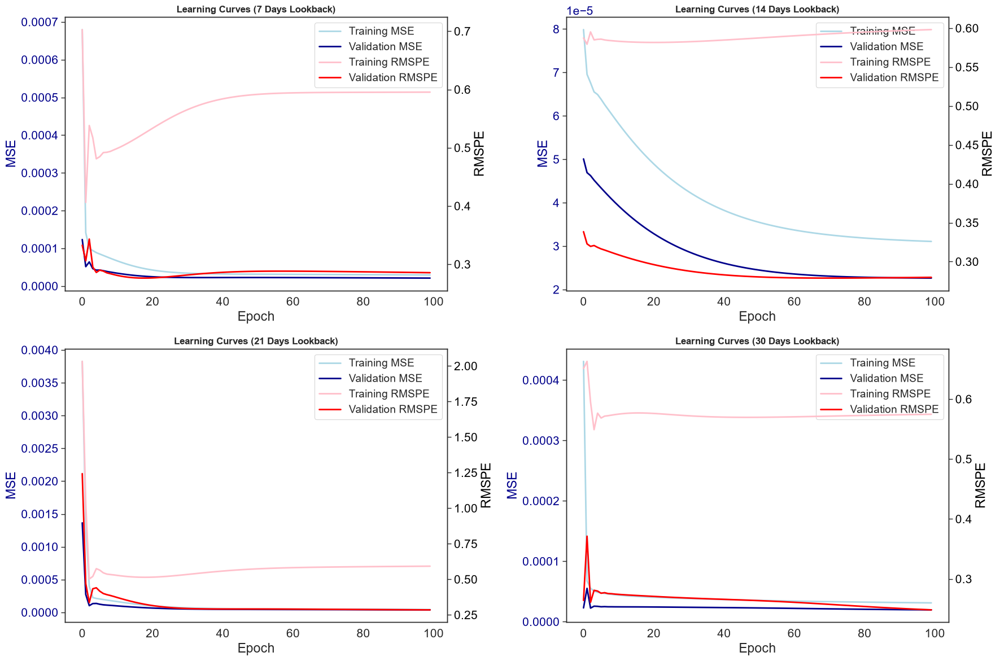

In [1124]:
viz_grid_train_val_metrics(histories, days)

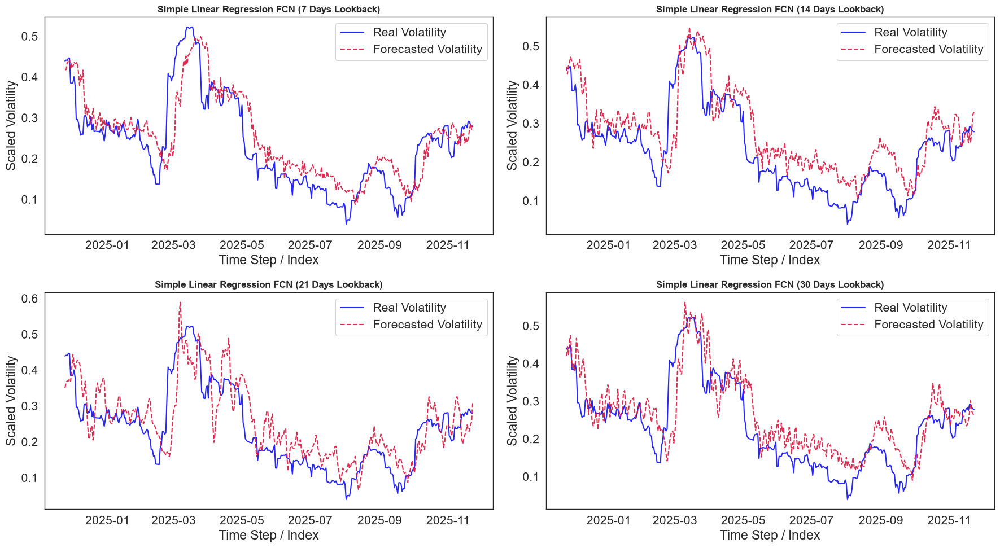

In [1125]:
# Pass predictions dictionary, target values, lookback days list, and model title
viz_grid_predictions(
    predictions_dict=predictions, 
    y_true=y_val_scaled, 
    days_list=days, 
    model_title="Simple Linear Regression FCN"
)

The forecast is tracing the current volatility line very closely, but is mostly lagging behind compared to my target values.

In [1127]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name="Simple Linear Regression Fully Connected Network",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)

In [1128]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866


A simple Fully Connected NN doesn't perform too bad. Validation RMSPE after 100 epochs of training and barely any tuning is already only a bit higher than best TARCH(1,2) model's RMSPE, and actually lower on RMSE.

### 4.2. Univariate Long Short-Term Memory (LSTM)**

(Reference: Geron (2019)

There's a class of Neural Networks called **Recurrent Neural Networks (RNN)** that can "predict the future". RNN works well with time series data, such as stock prices, and can even process sentences, documents, audio samples as inputs. Another application of RNN is in autonomic driving systems, where they're used to anticipate vehicle trajectories and help avoid accidents.

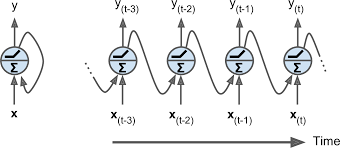

At each time step `t`, the recurrent neuron receives input $x_{t}$ as well as its own output from the previous time step $y_{t-1}$. Since the output of a Recurrent Neuron is a function of all the inputs from the previous time steps, it has a form of *memory* and able to preserve some information through time.

However, due to some transformations that the data goes through when traversing down RNN, some information is lost at each time step, and for a long sequence, the RNN's state contains virtually no information from the first inputs. 

**Long Short-Term Memory (LSTM)** was proposed in 1997 by Sepp Hochreiter and Jurgen Schmidhuber. The key part of LSTM is that the network can learn what's important and needs to be stored in the long-term state, and what can be ignored. LSTM looks very similar to a regular RNN cell, but its state is split into 2 vectors:
- $h_{t}$ - for short term state
- $c_{t}$ - for long term state

LSTM is a black box, and can be used like a basic Recurrent Neural Network (RNN) cell. However, it tends to perform much better, helps training converge faster, and also detect long-term dependencies in the data.

LSTM uses an **optimized implementation when running on a GPU**, that's why it's highly recommended to run this second part of the notebook on **Google Colab**.


First, I'm going to use the same lookback window `n_past` as the previous Neural Networks (30), and then depending on the result, I'll try to fine tune that value later.

The first LSTM model would be very simple with only 1 hidden LSTM layer of 20 units. I am using the standard `adam` optimizer here, and would later experiment with other optimizers if needed.

In [1132]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # 1. Clear session and set seed inside the loop for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_1 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        tf.keras.layers.LSTM(20),
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Compile model
    lstm_1.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    # 5. Callbacks (saving distinct checkpoint filenames for each n_past)
    checkpoint_cb = ModelCheckpoint(f'lstm_1_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe',
                                       mode='min')
    
    # 6. Fit Model
    lstm_1_res = lstm_1.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[checkpoint_cb, early_stopping_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_1_preds = forecast(lstm_1, val_idx, n_past)
    lstm_1_preds_scaled = scale(scaler_vol, lstm_1_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_1_res.history
    lstm_predictions[n_past] = lstm_1_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_1_res.history['loss'][-1],
        'Validation MSE': lstm_1_res.history['val_loss'][-1],
        'Training RMSPE': lstm_1_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_1_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 30ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 28ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000032        0.000023        0.592900   
14                          0.000034        0.000024        0.583514   
21                          0.000027        0.000020        0.585093   
30                          0.000026        0.000020        0.573754   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.292260  
14                              0.270113  
21                              0.261878  
30                              0.234078  


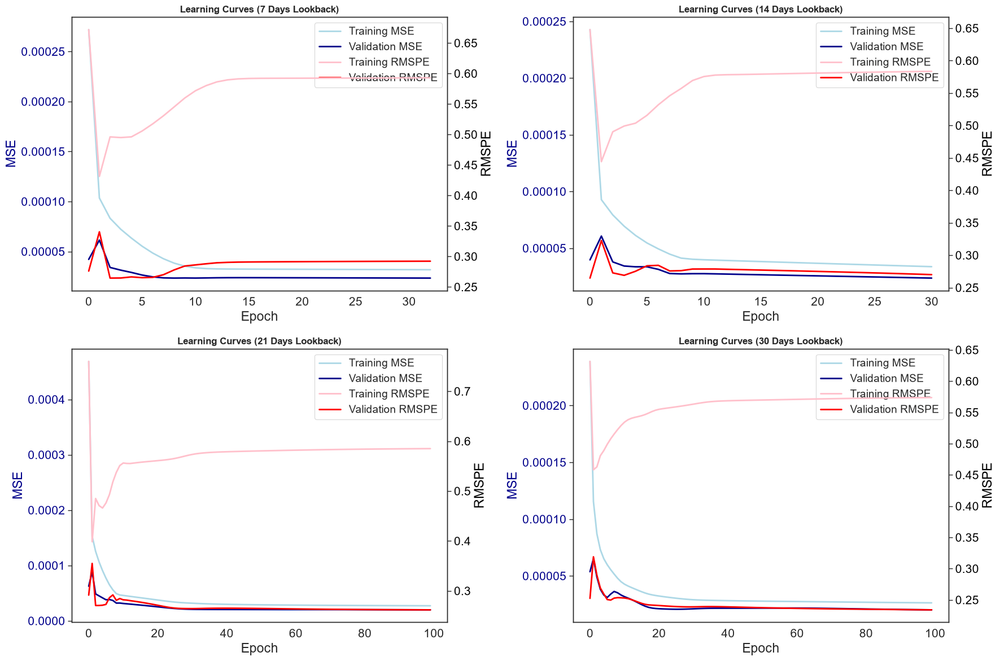

In [1133]:
# 1. Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

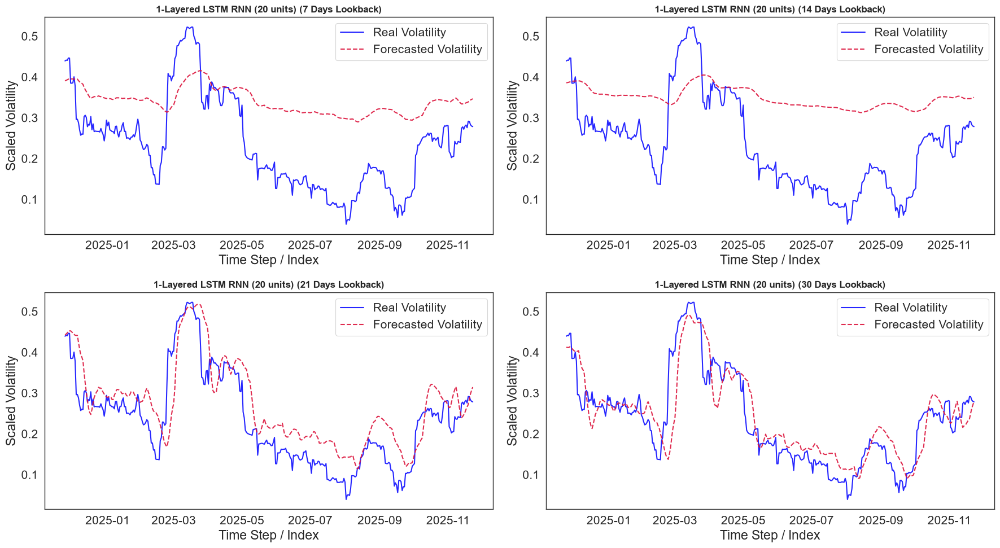

In [1134]:
#Target vs Predicted Grid for each lookback window
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="1-Layered LSTM RNN (20 units)")

Validation RMSPE is actually higher than Validation MSE, which is lower than Training MSE. But Training RMSPE, overall all the lines except for looks quite unstable.

Again, predictions traces `vol_current` quite closely, and the prediction line has smoothed out compared to the fully connected NN's predictions (meaning it's less noisy), but it is still also lagging behind compared to desired target.

In [1137]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="1-Layered LSTM 20 units",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795


Simple 1-layered LSTM is only a tiny bit better than fully connected network on RMSPE, and actually has higher RMSE than the simple LR NN above.

### 4.3. Univariate Bidirectional LSTM

(Reference: https://machinelearningmastery.com/develop-bidirectional-lstm-sequence-classification-python-keras/#:~:text=Bidirectional%20LSTMs%20are%20an%20extension,LSTMs%20on%20the%20input%20sequence)

Further research shows that there's an extension of LSTM cell called **Bidirectional LSTM**, which could potentially be better in this case by providing additional context to the models. Since all timesteps of the input sequence are already available, Bidirectional LSTM could train 2 instead of 1 LSTMs on the same input sequence:
- 1st one on the inputs as-is
- 2nd one on the reversed copy of the inputs

This could help provide additional context to the networks, and usually produces faster and fuller learning on the problem.

LSTM allows the maintenance of certain long-term memories across time, thereofore I'll extend `n_past` to 1 month, and also increase the number of hidden layers to see if the model can capture certain patterns better.

In [1140]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # CLEARING ANY INTERNAL VARIABLES TO PREVENT MODELS
    # FROM IMPACTING LATER VERSIONS OF THEMSELVES
    tf.keras.backend.clear_session()
    
    # SET SEED FOR REPRODUCIBILITY
    np.random.seed(seed)
    
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    lstm_2 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # ADDING 1st BIDIRECTIONAL LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # ADDING 2nd BIDIRECTIONAL LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # DENSE OUTPUT LAYER
        tf.keras.layers.Dense(1)
    ])
    
    lstm_2.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    checkpoint_cb = ModelCheckpoint('lstm_2.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', mode = 'min')
    
    # STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
    early_stopping_cb = EarlyStopping(patience=30,
                                      restore_best_weights=True,
                                      monitor='val_rmspe',mode='min')
     # 6. Fit Model
    lstm_2_res = lstm_2.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[checkpoint_cb, early_stopping_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_2_preds = forecast(lstm_2, val_idx, n_past)
    lstm_2_preds_scaled = scale(scaler_vol, lstm_2_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_2_res.history
    lstm_predictions[n_past] = lstm_2_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_2_res.history['loss'][-1],
        'Validation MSE': lstm_2_res.history['val_loss'][-1],
        'Training RMSPE': lstm_2_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_2_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)



12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000032        0.000024        0.595338   
14                          0.000028        0.000019        0.599769   
21                          0.000028        0.000018        0.586454   
30                          0.000024        0.000019        0.577643   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.299169  
14                              0.261984  
21                              0.253559  
30                              0.229674  


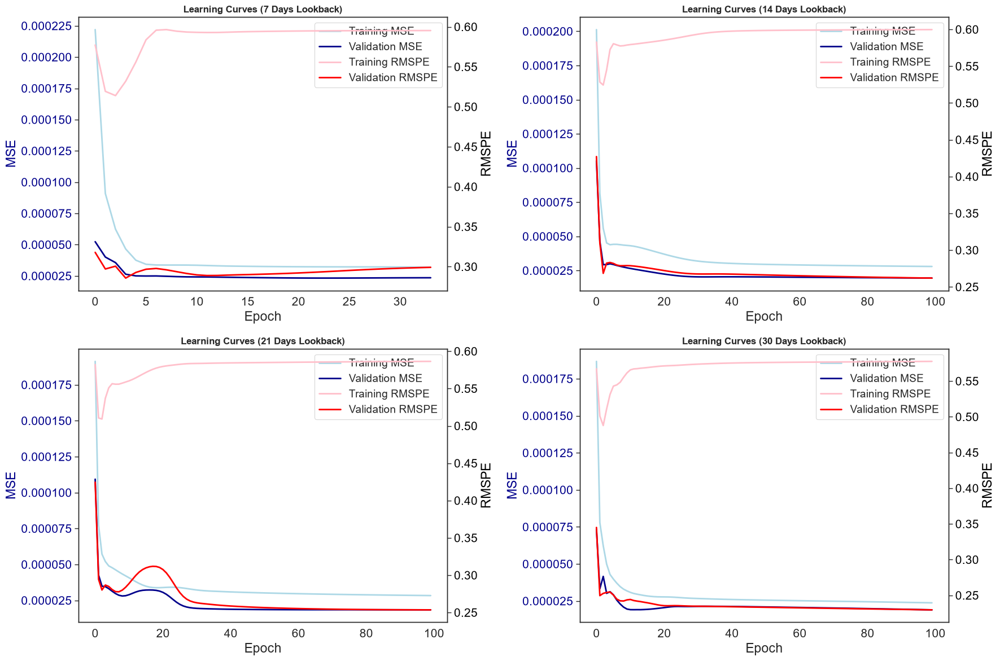

In [1141]:
# 1. Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

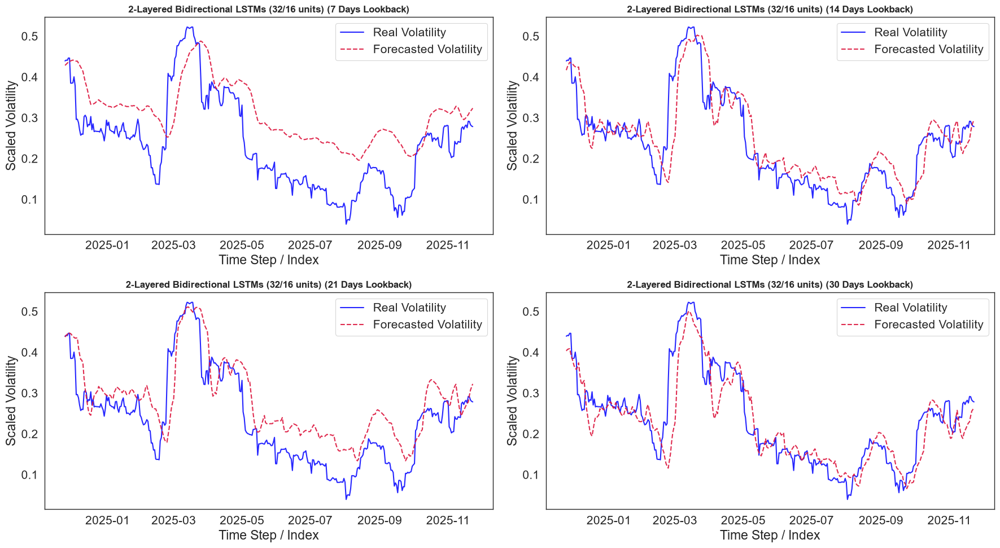

In [1149]:
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="2-Layered Bidirectional LSTMs (32/16 units)")

In [1186]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="2-Layered Bidirectional LSTMs (32/16 units)",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


2 Layered Bidirectional LSTMs with a lookback window of 30 days has managed to beat the best GARCH model (TARCH(2,2)) found above, which means I'm probably heading in the right direction!

In my Exploratory Notebooks I have experimented with different activation functions and network structures, such as:
- using `activation='relu'` or `activation='sigmoid'`
- increasing the number of hidden LSTM layers
- increasing number of units in each LSTM layer
- adding in Dropout layer with different dropout percentage
- changing `batch_size`

However, none of them have outperform the simple architecture above (2 layers of Bidirectional LSTMs with 32 and 16 units, and `n_past=30`). 

### 4.4. Univariate Bidirectional LSTM + 1D Convolutional Layer(s)

(Reference: Geron (2019))

A 1D convolutional layer slides several kernels across a sequence, producing a 1D feature map per kernel. Each kernel will learn to detect a single very short sequential pattern (no longer than the kernel size). 

Convolutional layers are supposed to allow lookback window extension, and help the model pick up patterns further in the past.

In [1193]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

batch_size = 64

for n_past in days:
    # CLEARING ANY INTERNAL VARIABLES TO PREVENT MODELS
    # FROM IMPACTING LATER VERSIONS OF THEMSELVES
    tf.keras.backend.clear_session()
    
    # SET SEED FOR REPRODUCIBILITY
    np.random.seed(seed)
    
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    lstm_3 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),
        # ADDING 1D CONVOLUTIONAL LAYER 
        tf.keras.layers.Conv1D(filters=32, kernel_size=4,
                               # DOWNSAMPLE INPUT SEQUENCE BY A FACTOR OF 2
                               strides=2, padding="valid",    
                               activation="relu",
                               input_shape=[None, 1]),                            
        # ADDING 1st LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, activation='relu',
                                                           return_sequences=True)),
        # ADDING 2nd LSTM LAYER
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16, activation='relu')),
    
        # DENSE OUTPUT LAYER
        tf.keras.layers.Dense(1)
    ])
    
    lstm_3.compile(loss='mse', 
                   optimizer="adam", 
                   metrics=[rmspe])
    
    checkpoint_cb = ModelCheckpoint('lstm_3.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', mode = 'min')
    
    # STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
    early_stopping_cb = EarlyStopping(patience=30,
                                      restore_best_weights=True,
                                      monitor='val_rmspe', mode = 'min')
    
    # 6. Fitting model to Training Data
    lstm_3_res = lstm_3.fit(mat_X_train, mat_y_train, 
                        callbacks=[checkpoint_cb, early_stopping_cb],
                        validation_split=0.2, shuffle=True,
                        verbose=0, batch_size=batch_size, epochs=100)

    # 7. Forecast and scale predictions
    lstm_3_preds = forecast(lstm_3, val_idx, n_past)
    lstm_3_preds_scaled = scale(scaler_vol, lstm_3_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_3_res.history
    lstm_predictions[n_past] = lstm_3_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_3_res.history['loss'][-1],
        'Validation MSE': lstm_3_res.history['val_loss'][-1],
        'Training RMSPE': lstm_3_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_3_res.history['val_rmspe'][-1]
    })

# Summary matrix for LSTM training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print("=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===")
print(lstm_results_df)

    
        

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 89ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (LSTM) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000034        0.000026        0.592889   
14                          0.000038        0.000027        0.585802   
21                          0.000035        0.000032        0.568249   
30                          0.000025        0.000022        0.576674   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.296393  
14                              0.275520  
21                              0.313703  
30                              0.241870  


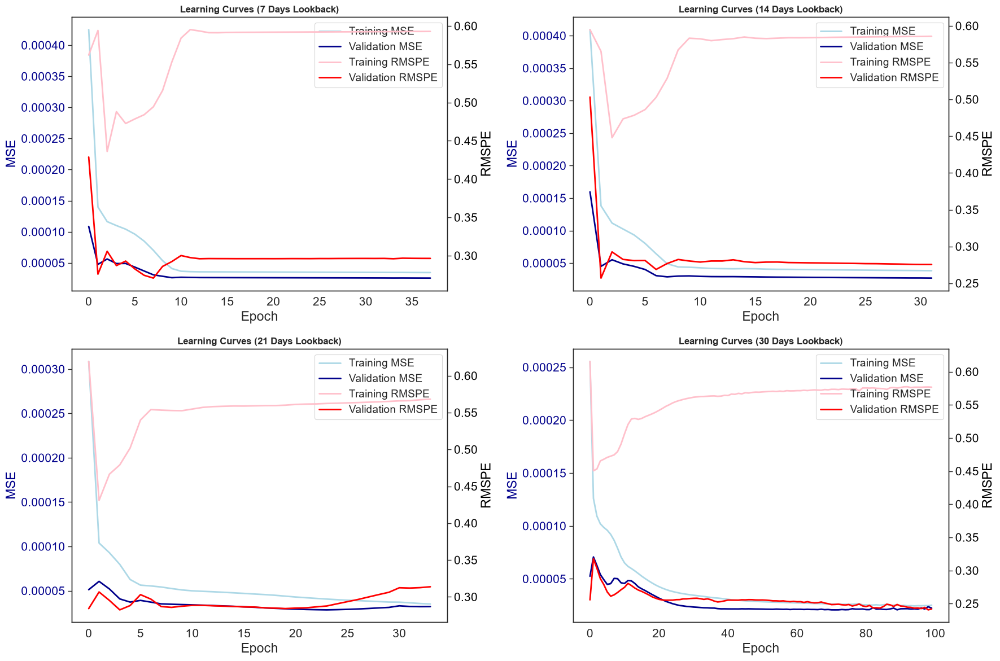

In [1194]:
# Render 2x2 Learning Curves Grid (MSE & RMSPE)
viz_grid_train_val_metrics(lstm_histories, days)

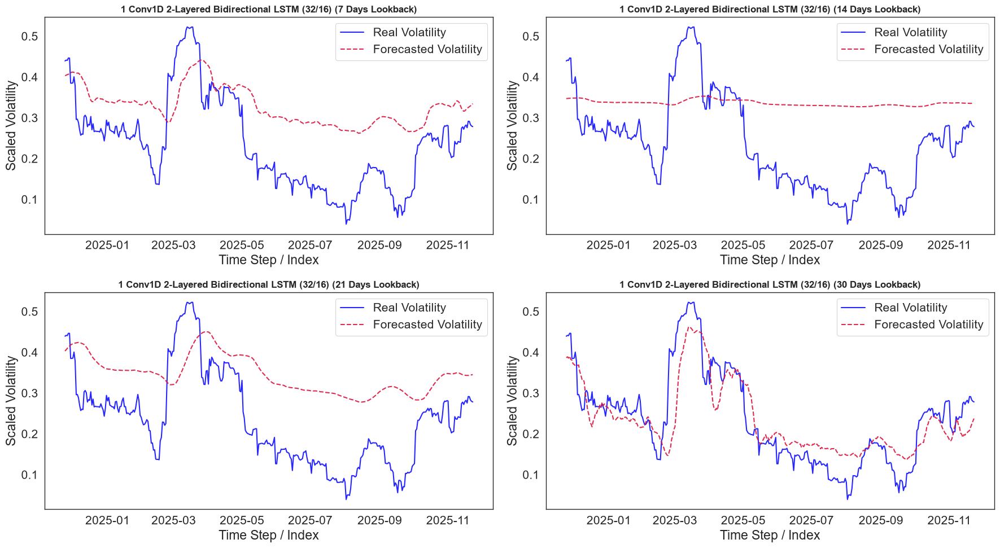

In [1195]:
#2 Target vs Forecasted Volatility
viz_grid_predictions(lstm_predictions, y_val_scaled, days, model_title="1 Conv1D 2-Layered Bidirectional LSTM (32/16)")

In [1196]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


In [1197]:
# Log metrics to global performance comparison DataFrame
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_predictions,
    days_list=days,
    model_base_name="1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units)",
    target_df=nn_perf_df  # Pass existing dataframe to append rows
)
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


### 4.5. Learning Rate Tuning with SGD Optimizer

So far I have only used the standard `adam` optimizer. It'd be interesting to see how the model performs on a more customizable optimizer like **Stochastic Gradient Descent (SGD)**. I will continue this with the most successful LSTM architecture so far (2 layers of Bidirectional LSTMs with 32 and 16 units and a lookback window of 30 days).

In [1200]:
lstm_histories = {}
lstm_predictions = {}
lstm_results_list = []

from tensorflow.keras.callbacks import LearningRateScheduler

MODEL_NAME = "Stacked Bidirectional LSTM (32-16 units)"
SAVE_PREFIX = "lstm_4"

for n_past in days:
    # 1. Clear session and set seed inside the loop for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_4 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # 1st Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # 2nd Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Optimizer & Learning Rate Schedule
    lr_schedule = LearningRateScheduler(lambda epoch: 1e-8 * 10**(epoch / 20))
    optimizer = tf.keras.optimizers.SGD(learning_rate=1e-8, momentum=0.9)
    lstm_4.compile(loss='mse', optimizer=optimizer, metrics=[rmspe])
    
    # 5. Checkpoint Callback (unique filename per window)
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    # 6. Fit Model
    lstm_4_res = lstm_4.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100, 
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True,
        callbacks=[lr_schedule, checkpoint_cb]
    )
    
    # 7. Forecast and scale predictions
    lstm_4_preds = forecast(lstm_4, val_idx, n_past)
    lstm_4_preds_scaled = scale(scaler_vol, lstm_4_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_histories[n_past] = lstm_4_res.history
    lstm_predictions[n_past] = lstm_4_preds_scaled
    
    # 9. Log training/val metrics
    lstm_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_4_res.history['loss'][-1],
        'Validation MSE': lstm_4_res.history['val_loss'][-1],
        'Training RMSPE': lstm_4_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_4_res.history['val_rmspe'][-1]
    })

    # Summary matrix for training performance
lstm_results_df = pd.DataFrame(lstm_results_list).set_index('Lookback Window (Days)')
print(f"=== LOOKBACK WINDOW EVALUATION MATRIX ({MODEL_NAME}) ===")
print(lstm_results_df)

12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 83ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 90ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (Stacked Bidirectional LSTM (32-16 units)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000118        0.000056        0.468725   
14                          0.000173        0.000079        0.479197   
21                          0.000083        0.000044        0.470446   
30                          0.000140        0.000068        0.454890   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.299715  
14                              0.319656  
21                              0.278692  
30                              0.299998  


In [1201]:
from decimal import Decimal
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

best_lr = 6.9e-5
def viz_grid_learning_rate(histories_dict, days_list, model_title="Stacked Bi-LSTM"):
    """Plots a 2x2 grid of Loss & RMSPE vs.

    Learning Rate (semilogx) for tuning optimal learning rate across lookback
    windows.
    """

     
    with sns.axes_style("white"):
        fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
        axes_flat = axes.flatten()

        for i, n_past in enumerate(days_list):
            ax1 = axes_flat[i]
            hist = histories_dict[n_past]

            # 1. LEFT Y-AXIS: Training MSE (Semilog scale for Learning Rate)
            ln1 = ax1.semilogx(
                hist["learning_rate"], hist["loss"], color="red", label="MSE", lw=1.5
            )
            ax1.set_xlabel("Learning Rate", fontsize=11)
            ax1.set_ylabel("Training MSE", color="red", fontsize=11)
            ax1.tick_params(axis="y", labelcolor="red")

            # 2. RIGHT Y-AXIS: Training RMSPE
            ax2 = ax1.twinx()
            ln2 = ax2.semilogx(
                hist["learning_rate"], hist["rmspe"], color="blue", label="RMSPE", lw=1.5
            )
            ax2.set_ylabel("Training RMSPE", color="blue", fontsize=11)
            ax2.tick_params(axis="y", labelcolor="blue")

            # 3. LOCATE OPTIMAL LEARNING RATE (Min MSE)
            min_loss_idx = np.argmin(hist["loss"])
            best_lr = hist["learning_rate"][min_loss_idx]
            min_loss = hist["loss"][min_loss_idx]
            max_loss = np.max(hist["loss"])

            # Vertical guide line at best LR
            ax1.vlines(
                x=best_lr,
                ymin=min_loss,
                ymax=max_loss * 0.8,
                colors="black",
                linestyles="--",
                lw=1,
            )
            ax1.text(
                best_lr * 0.5,
                max_loss * 0.85,
                f"Best LR: {'%.2E' % Decimal(str(best_lr))}",
                fontsize=10,
                fontweight="bold",
                bbox=dict(
                    boxstyle="round,pad=0.3", facecolor="yellow", alpha=0.3
                ),
            )

            # 4. COMBINED LEGEND
            lns = ln1 + ln2
            labs = [l.get_label() for l in lns]
            ax1.legend(lns, labs, loc="lower left", frameon=True)

            ax1.set_title(
                f"{model_title} LR Tuning ({n_past} Days)",
                fontsize=12,
                fontweight="bold",
            )

        plt.tight_layout()
        plt.show()

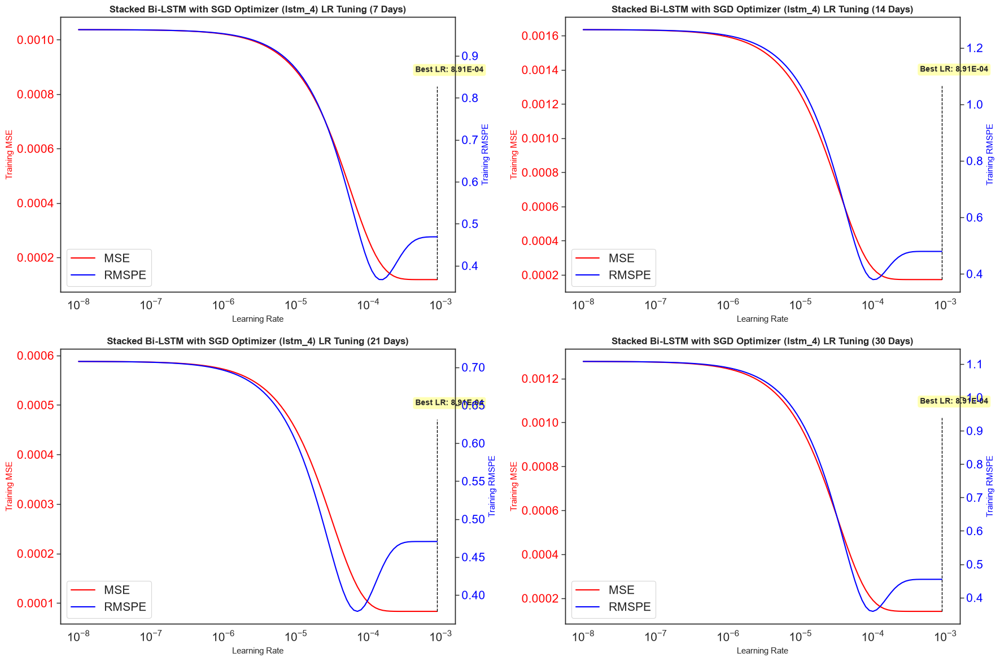

In [1202]:
# Call LR Grid Plotter for lstm_4 across all 4 lookback windows
viz_grid_learning_rate(
    histories_dict=lstm_histories,
    days_list=days,
    model_title="Stacked Bi-LSTM with SGD Optimizer (lstm_4)",
)

## Learning Rate Optimization Analysis
The optimal learning rate baseline for this model across lookback windows is determined to be $1.0 \times 10^{-4}$.   Based on the empirical learning rate finder plot:   Loss Alignment: Both the Training MSE (red) and Training RMSPE (blue) exhibit a sharp, synchronized downward trajectory between $1.0 \times 10^{-6}$ and $1.0 \times 10^{-4}$.   Stability Limits: While the MSE loss curve plateaus smoothly all the way up to $8.91 \times 10^{-4}$ (the point of minimum MSE), the RMSPE metric achieves its absolute local minimum near $1.0 \times 10^{-4}$ before introducing mild optimization noise and rising. Past $8.91 \times 10^{-4}$, both metrics hit the boundary and risk explosive divergence.   Following industry-standard deep learning workflows, we avoid selecting the absolute minimum point right at the precipice of divergence (such as $8.91 \times 10^{-4}$). Instead, a learning rate of $1.0 \times 10^{-4}$ is chosen because it sits directly in the center of the steepest downward gradient for both curves and aligns with the minimum RMSPE. This strikes the ideal balance between aggressive gradient steps and long-term training stability.   Next, the Stacked Bi-LSTM model will be re-trained utilizing this optimized learning rate baseline. 

In [1204]:
# Optimized learning rate selected from the tuning curve
best_lr = 1e-4

lstm_4_histories = {}
lstm_4_predictions = {}
lstm_4_results_list = []

MODEL_NAME = "Stacked Bi-LSTM (Tuned LR=1e-4)"
SAVE_PREFIX = "lstm_4_tuned"

for n_past in days:
    # 1. Clear session and set seed for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Dataset windowing for current lookback window
    mat_X_train, mat_y_train = windowed_dataset(x_train, y_train, n_past)
    
    # 3. Model definition
    lstm_4 = tf.keras.models.Sequential([
        tf.keras.layers.Lambda(lambda x: tf.expand_dims(x, axis=-1), 
                               input_shape=[None]),                            
        # 1st Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        # 2nd Bidirectional LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])
    
    # 4. Compile with fixed best_lr
    optimizer = tf.keras.optimizers.SGD(learning_rate=best_lr, momentum=0.9)
    lstm_4.compile(loss='mse', optimizer=optimizer, metrics=[rmspe])
    
    # 5. Callbacks per window
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe',
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe',
                                       mode='min')

    # 6. Fit Model (200 epochs as per updated setup)
    lstm_4_res = lstm_4.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=200, 
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2, 
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )
    
    # 7. Forecast and scale predictions
    lstm_4_preds = forecast(lstm_4, val_idx, n_past)
    lstm_4_preds_scaled = scale(scaler_vol, lstm_4_preds)
        
    # 8. Store histories & predictions for grid plotting
    lstm_4_histories[n_past] = lstm_4_res.history
    lstm_4_predictions[n_past] = lstm_4_preds_scaled
    
    # 9. Log training/val metrics
    lstm_4_results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_4_res.history['loss'][-1],
        'Validation MSE': lstm_4_res.history['val_loss'][-1],
        'Training RMSPE': lstm_4_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_4_res.history['val_rmspe'][-1]
    })

# Matrix display for tuned LSTM training performance
lstm_4_results_df = pd.DataFrame(lstm_4_results_list).set_index('Lookback Window (Days)')
print(f"=== LOOKBACK WINDOW EVALUATION MATRIX ({MODEL_NAME}) ===")
print(lstm_4_results_df)


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 109ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 94ms/step
=== LOOKBACK WINDOW EVALUATION MATRIX (Stacked Bi-LSTM (Tuned LR=1e-4)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000151        0.000070        0.468298   
14                          0.000113        0.000054        0.468996   
21                          0.000107        0.000052        0.456295   
30                          0.000131        0.000060        0.451943   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.317477  
14                              0.285186  
21                              0.281720  
30                              0.288125  


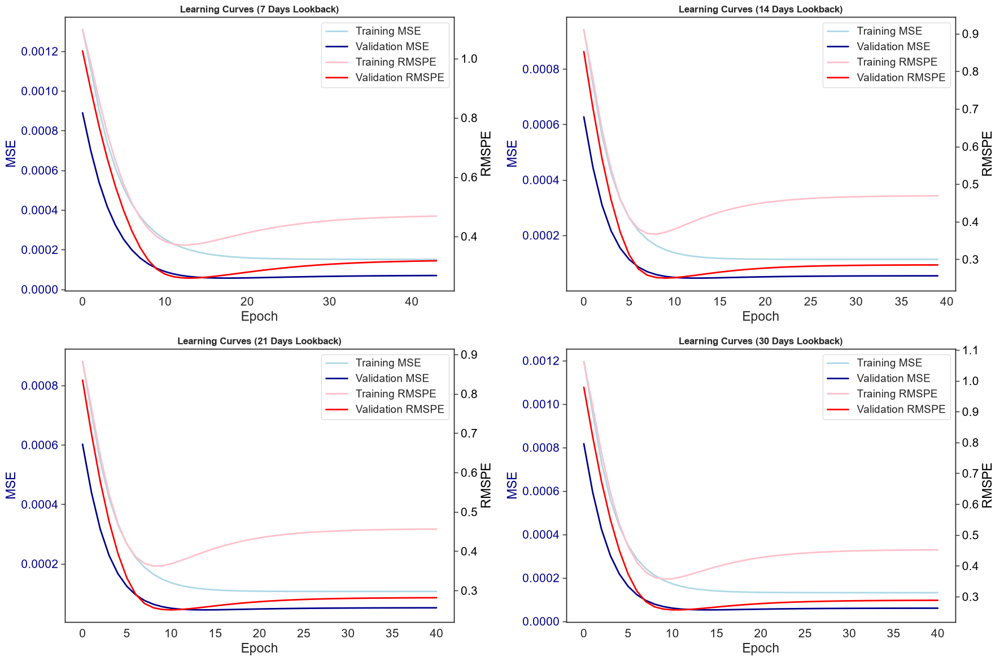

In [1205]:
# --- VISUALIZATIONS & PERFORMANCE LOGGING ---
# Learning curves 2x2 grid (MSE & RMSPE vs Epochs)
viz_grid_train_val_metrics(lstm_4_histories, days)


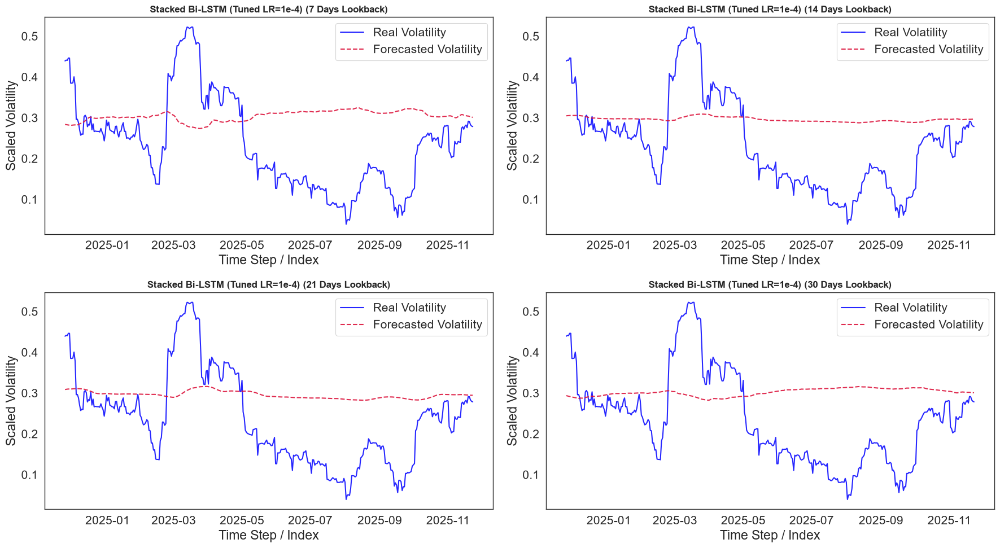

In [1206]:
# 2. Real vs Forecast 2x2 grid
viz_grid_predictions(lstm_4_predictions, y_val_scaled, days, model_title=MODEL_NAME)


In [1207]:
# 3. Log to global performance table
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=lstm_4_predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


Training RMSPE started going up after epoch 5, but surprisingly everything else (including Validation RMSPE) continues to go down until epoch 15 where performance stopped progressing.

This customized optimizer seems to prioritize volatility's long-term tendency to revert to the mean. Hence the predictions hovers where the mean is.

The settings for SGD optimizer using best learning rate found above did not seem to yield better results than the `adam` optimizer, so going forward I will stick with `adam`.

### 4.6. Multivariate LSTM

So far I have only using simple 1-dimensional inputs for all of my models, and for financial data, this is likely insufficient. That could be the reason why most of the above models seems failed to yield better result than Naive Forecasting. It doesn't matter how many neurons or hidden layers are used, or how complex the model's architectures are, inadequate data is most likely not going to produce good results.

For the next section, I'll attempt to create Multivariate Neural Networks to see if additional features could help improve performance.

In [1212]:
df.head()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
2021-01-31,34270.878906,34288.332031,32270.175781,33114.359375,52754542671,-3.370820,-0.034289,0.056789,0.051557
2021-02-01,33114.578125,34638.214844,32384.228516,33537.175781,61400400660,1.276837,0.012688,0.054349,0.060580
2021-02-02,33533.199219,35896.882812,33489.218750,35510.289062,63088585433,5.883361,0.057168,0.055249,0.059923
2021-02-03,35510.820312,37480.187500,35443.984375,37472.089844,61166818159,5.524598,0.053774,0.055952,0.058604
2021-02-04,37475.105469,38592.175781,36317.500000,36926.066406,68838074392,-1.457147,-0.014679,0.054850,0.059166


In [1213]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1788 entries, 2021-01-31 to 2025-12-23
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Open         1788 non-null   float64
 1   High         1788 non-null   float64
 2   Low          1788 non-null   float64
 3   Close        1788 non-null   float64
 4   Volume       1788 non-null   int64  
 5   returns      1788 non-null   float64
 6   log_returns  1788 non-null   float64
 7   vol_current  1788 non-null   float64
 8   vol_future   1788 non-null   float64
dtypes: float64(8), int64(1)
memory usage: 204.2 KB


In [1214]:
df.describe()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future
count,1788.000000,1788.000000,1788.000000,1788.000000,1.788000e+03,1788.000000,1788.000000,1788.000000,1788.000000
mean,54579.054230,55631.989300,53461.872055,54606.916449,3.665953e+10,0.097486,0.000524,0.029050,0.028914
std,29574.406656,29995.093258,29120.969736,29580.642625,2.276151e+10,3.005709,0.030045,0.010602,0.010495
min,15782.300781,16253.047852,15599.046875,15787.284180,5.331173e+09,-15.974726,-0.174053,0.009005,0.009005
25%,29249.734375,29675.687500,28920.612305,29268.411133,2.119191e+10,-1.309413,-0.013181,0.021597,0.021421
50%,46824.806641,48013.591797,45626.160156,46815.810547,3.148331e+10,-0.002230,-0.000022,0.026991,0.026865
75%,69171.253906,70162.619141,68031.761719,69271.777344,4.605740e+10,1.472414,0.014617,0.035055,0.034986
max,124752.140625,126198.070312,123196.046875,124752.531250,3.509679e+11,18.746474,0.171821,0.064581,0.064581


#### 4.6.1. Feature Engineering

The Open/High/Low/Close prices are usually very similar and highly correlated to each other. Therefore, instead of keeping all of them in the dataset, I would add 2 more features:
- **High-Low Spread** - which is the logarithm of the difference between the Highest and Lowest prices intraday as a percentage of the Closing price
- **Open-Close Spread** - which is the difference between the Close and Open prices intraday as a percentage of the Closing price

and then for Volume:
- Volume column has very large values that are billions/millions of times larger than the other features. Therefore I'm going to the get `np.log()` of it, and hopefully transform it into a more normal looking distribution.

and eliminate the three `Close`, `Open`, `High`, `Low` columns.

In [1216]:
df['HL_sprd'] = np.log((df.High - df.Low) / df.Close)
df['CO_sprd'] = (df.Close - df.Open) / df.Open
df['Volume'] = np.log(df.Volume)

In [1217]:
df.head()

,Open,High,Low,Close,Volume,returns,log_returns,vol_current,vol_future,HL_sprd,CO_sprd
2021-01-31,34270.878906,34288.332031,32270.175781,33114.359375,24.688916,-3.370820,-0.034289,0.056789,0.051557,-2.797783,-0.033746
2021-02-01,33114.578125,34638.214844,32384.228516,33537.175781,24.840682,1.276837,0.012688,0.054349,0.060580,-2.699954,0.012762
2021-02-02,33533.199219,35896.882812,33489.218750,35510.289062,24.867806,5.883361,0.057168,0.055249,0.059923,-2.691165,0.058959
2021-02-03,35510.820312,37480.187500,35443.984375,37472.089844,24.836871,5.524598,0.053774,0.055952,0.058604,-2.912510,0.055230
2021-02-04,37475.105469,38592.175781,36317.500000,36926.066406,24.955023,-1.457147,-0.014679,0.054850,0.059166,-2.787080,-0.014651


These numeric features will need to be normalized later since LSTM uses `sigmoid` and `tanh` activation functions, which is very sensitive magnitude.

Since `vol_current` is already derived from `log_returns`, I am not going to include `log_returns` in my model.

In [1240]:
features = ['HL_sprd', 'CO_sprd', 'Volume', 'vol_current']

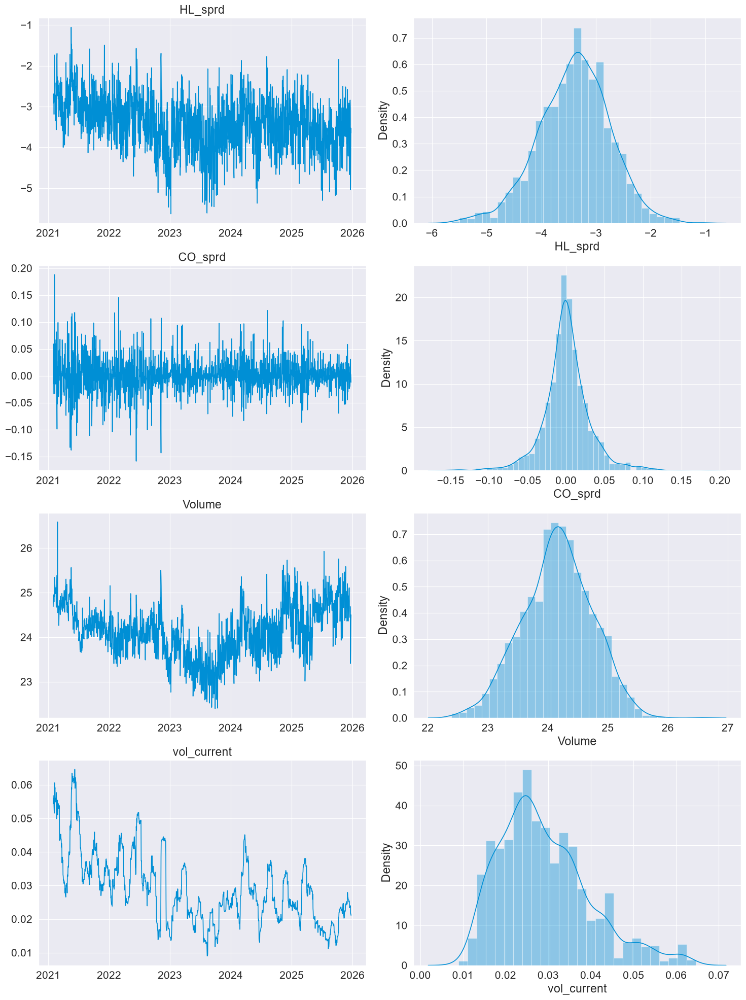

In [1242]:
# PLOT EACH NUMERICAL COLUMN
with sns.axes_style("darkgrid"):
    fig, axes = plt.subplots(nrows=4, ncols=2, figsize=(15,20))

    for i, c in enumerate(features):
        ax1, ax2 = axes[i][0], axes[i][1]
        ax1.plot(df[c])
        ax1.set_title(c)

        sns.distplot(df[c], ax=ax2)

    plt.tight_layout()
#    plt.savefig(os.path.join(directory_to_img, 'features.png'), 
 #               dpi=300, bbox_inches='tight')
    plt.show();

#### 4.6.2. Input Reshaping

The predict here would be to predict next 7 days' volatility (`vol_future`) column using 4 input variables:
1. `HL_sprd`
2. `CO_sprd`
3. `Volume`
4. `vol_current`

Reshaping the inputs is the meat of these Multivariate LSTM. Generally speaking, inputs for LSTM should be in the shape of:


**`[batch_size, n_past, input_dims]`**



in which:

- **`batch_size`** is the number of datapoints in each batch
- **`n_past`** is the number of past time steps to be used for prediction (I'll use the same value as above for now).
- **`input_dims`** is the number of input features (which is 4 in this case)  

In [1245]:
# SEPARATE INPUT DATAFRAME FROM df
input_df = df[features]

# SEPARATE INPUTS FOR TRAINING SET ONLY
X_train = input_df.loc[train_idx]

In [1246]:
X_train.head()

,HL_sprd,CO_sprd,Volume,vol_current
2021-01-31,-2.797783,-0.033746,24.688916,0.056789
2021-02-01,-2.699954,0.012762,24.840682,0.054349
2021-02-02,-2.691165,0.058959,24.867806,0.055249
2021-02-03,-2.912510,0.055230,24.836871,0.055952
2021-02-04,-2.787080,-0.014651,24.955023,0.054850


In [1247]:
input_df.head()

,HL_sprd,CO_sprd,Volume,vol_current
2021-01-31,-2.797783,-0.033746,24.688916,0.056789
2021-02-01,-2.699954,0.012762,24.840682,0.054349
2021-02-02,-2.691165,0.058959,24.867806,0.055249
2021-02-03,-2.912510,0.055230,24.836871,0.055952
2021-02-04,-2.787080,-0.014651,24.955023,0.054850


In [1248]:
X_train.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1393 entries, 2021-01-31 to 2024-11-23
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HL_sprd      1393 non-null   float64
 1   CO_sprd      1393 non-null   float64
 2   Volume       1393 non-null   float64
 3   vol_current  1393 non-null   float64
dtypes: float64(4)
memory usage: 54.4 KB


In [1249]:
input_df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1788 entries, 2021-01-31 to 2025-12-23
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   HL_sprd      1788 non-null   float64
 1   CO_sprd      1788 non-null   float64
 2   Volume       1788 non-null   float64
 3   vol_current  1788 non-null   float64
dtypes: float64(4)
memory usage: 134.4 KB


In [1250]:
def forecast_multi(model, range_idx, n_past):
    start_idx = range_idx[0] - timedelta(n_past - 1)
    end_idx = range_idx[-1]
    mat_X, _ = windowed_dataset(input_df[start_idx:end_idx], 
                                df.vol_future[range_idx], n_past)
    preds = pd.Series(model.predict(mat_X)[:, 0],
                      index=range_idx)

    return preds

### 4.7. Multivariate 2-Layered Bidirectional LSTM with Dropout

My first Multivariate LSTM model would be relatively simple with 2 hidden layers of Bidirectional LSTM (quite similar to the Univariate structure above). However, I will also include Dropout layers in between. Having more features means the model would be more prone to **overfitting**, and Dropout layers can help reduce that.

In [1252]:
# Model Metadata
MODEL_NAME = "Multivariate Stacked Bi-LSTM (lstm_5)"
SAVE_PREFIX = "lstm_5"

# --- RESET COMMON CONTAINERS AT THE START OF NEW MODEL ---
histories = {}
predictions = {}
results_list = []

# --- LOOP OVER ALL LOOKBACK WINDOWS ---
for n_past in days:
    # 1. Clear session and set seeds for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Windowed dataset slice (multivariate features)
    mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)
    n_dims = mat_X_train.shape[-1]  # Infer feature dimension dynamically
    
    # 3. Define Architecture
    lstm_5 = tf.keras.models.Sequential([ 
        tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
        tf.keras.layers.LayerNormalization(), 

        # 1st LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 2nd LSTM Layer
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        tf.keras.layers.Dropout(0.1),

        # Output Layer
        tf.keras.layers.Dense(1)
    ])

    # 4. Compile
    lstm_5.compile(loss='mse', optimizer='adam', metrics=[rmspe])

    # 5. Callbacks with dynamic window saving
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', 
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe', 
                                       mode='min')

    # 6. Fit Model
    lstm_5_res = lstm_5.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100,
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2,
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )

    # 7. Forecast and scale predictions
    lstm_5_preds = forecast_multi(lstm_5, val_idx, n_past)
    lstm_5_preds_scaled = scale(scaler_vol, lstm_5_preds)
        
    # 8. Store outputs in common containers
    histories[n_past] = lstm_5_res.history
    predictions[n_past] = lstm_5_preds_scaled
    
    # 9. Record metrics per window
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_5_res.history['loss'][-1],
        'Validation MSE': lstm_5_res.history['val_loss'][-1],
        'Training RMSPE': lstm_5_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_5_res.history['val_rmspe'][-1]
    })

# --- OUTPUT & VISUALIZATIONS ---
print(f"=== LOOKBACK EVALUATION MATRIX ({MODEL_NAME}) ===")
print(pd.DataFrame(results_list).set_index('Lookback Window (Days)'))



12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step
=== LOOKBACK EVALUATION MATRIX (Multivariate Stacked Bi-LSTM (lstm_5)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000106        0.000041        0.634405   
14                          0.000117        0.000024        0.670405   
21                          0.000092        0.000041        0.648313   
30                          0.000112        0.000022        0.649788   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.325762  
14                              0.267570  
21                              0.318875  
30                              0.242920  


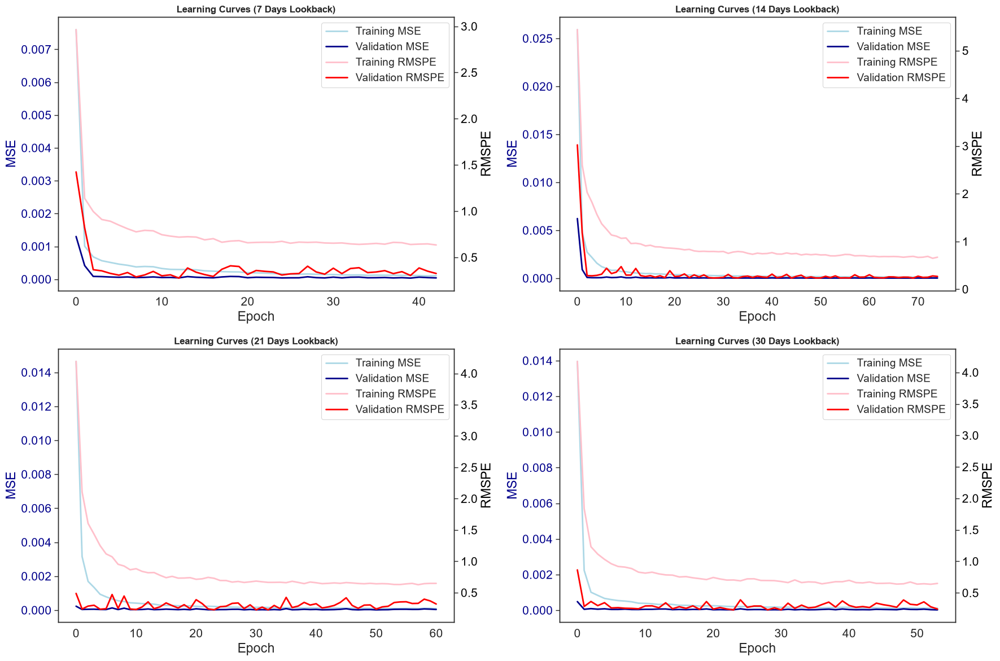

In [1253]:
# 1. Plot Learning Curves Grid
viz_grid_train_val_metrics(histories, days)


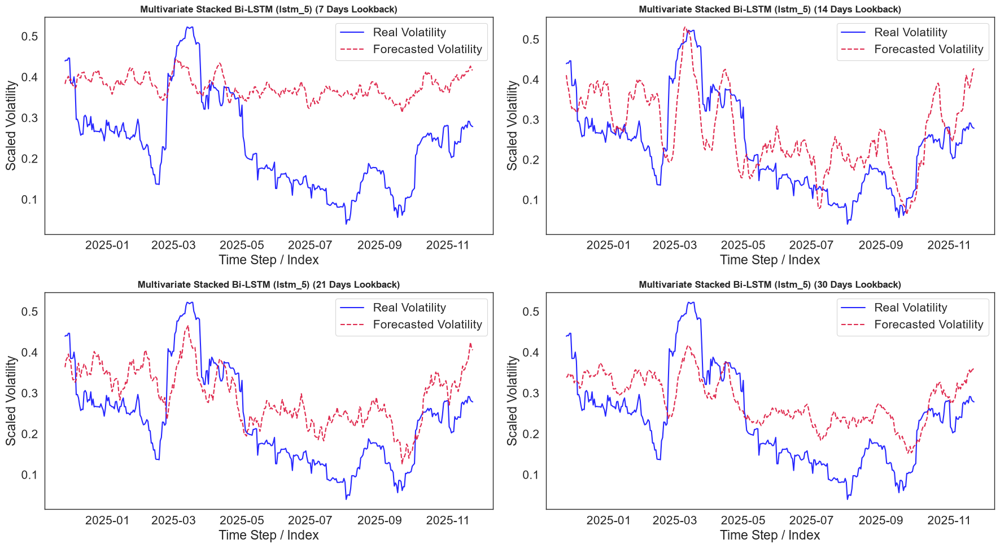

In [1254]:
# 2. Plot Forecast vs. Real Grid
viz_grid_predictions(predictions, y_val_scaled, days, model_title=MODEL_NAME)

In [1255]:
# 3. Append to Global Leaderboard
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


In [1257]:
tf.keras.backend.clear_session()

# SET SEED FOR REPRODUCIBILITY
np.random.seed(seed)

n_past = 30
batch_size = 64
n_dims = input_df.shape[1]

mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)

# CONSTRUCTING MULTIVARIATE BIDIRECTIONAL LSTM NN
lstm_5 = tf.keras.models.Sequential([ 
    tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
    # BATCH NORMALIZATION
    tf.keras.layers.BatchNormalization(), 

    # ADDING 1st LSTM LAYER
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
    tf.keras.layers.Dropout(0.1),

    # ADDING 2nd LSTM LAYER
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
    tf.keras.layers.Dropout(0.1),

    # DENSE OUTPUT LAYER
    tf.keras.layers.Dense(1)
])

lstm_5.compile(loss='mse', 
               optimizer="adam", 
               metrics=[rmspe])

checkpoint_cb = ModelCheckpoint('lstm_5.h5',
                                save_best_only=True,
                                monitor='val_rmspe', mode='min')

# STOPPING THE TRAINING IF VALIDATION RMSPE IS NOT IMPROVING 
early_stopping_cb = EarlyStopping(patience=30,
                                  restore_best_weights=True,
                                  monitor='val_rmspe', mode='min')

print(lstm_5.summary())

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ batch_normalization                  │ (None, 30, 4)               │              16 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional (Bidirectional)        │ (None, 30, 64)              │           9,472 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 30, 64)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ bidirectional_1 (Bidirectional)      │ (None, 32)                  │          10,368 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │              33 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 19,889 (77.69 KB)

 Trainable params: 19,881 (77.66 KB)

 Non-trainable params: 8 (32.00 B)

None


The prediction line has moved horizontally more towards target lines, and has actually traced the desired output very closely between November 2020 to February 2021. This is certainly an improvement compared to all the previous model. It also doesn't look as noisy as some of the other ones.

<img src="https://bluejaysnation.com/wp-content/uploads/sites/8/2019/09/im-not-crying-youre-crying.jpg " width="200" />

This is the first model with a Validation RMSPE sub 1.0, but it's actually still than 1Conv1D Bidirectional LSTM  which is the best model found above (Univariate LSTM with 2 layers). 

(I have also experimented with adding 1D convolutional layers to this Multivariate LSTM models, which is available in the Exploratory Notebooks folder, but it did not produce better results, so I am going to omit that version here).

### 4.8. Multivariate 3-Layered Bidirectional LSTM

Next, I'm going to add more LSTM layers to see if that helps improve performance.

In [1261]:
nn_perf_df = nn_perf_df.iloc[:-4]
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


In [1265]:
# Model Metadata
MODEL_NAME = "Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization)"
SAVE_PREFIX = "lstm_6"

# Reset common containers for new model
histories = {}
predictions = {}
results_list = []

for n_past in days:
    # 1. Clear session and set seed for reproducibility
    tf.keras.backend.clear_session()
    np.random.seed(seed)
    tf.random.set_seed(seed)
    
    # 2. Windowed dataset slice (multivariate features)
    mat_X_train, mat_y_train = windowed_dataset(X_train, y_train, n_past)
    n_dims = mat_X_train.shape[-1]
    
    # 3. Model Definition (3-Layer Stacked Bi-LSTM)
    lstm_6 = tf.keras.models.Sequential([  
        tf.keras.layers.InputLayer(input_shape=[n_past, n_dims]),
        tf.keras.layers.LayerNormalization(), 
        
        # 1st Bi-LSTM Layer (64 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 2nd Bi-LSTM Layer (32 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(32, return_sequences=True)),
        tf.keras.layers.Dropout(0.1),

        # 3rd Bi-LSTM Layer (16 units)
        tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(16)),
        tf.keras.layers.Dropout(0.1),
        
        # Dense Output Layer
        tf.keras.layers.Dense(1)
    ])

    # 4. Compile
    lstm_6.compile(loss='mse', optimizer='adam', metrics=[rmspe])

    # 5. Callbacks
    checkpoint_cb = ModelCheckpoint(f'{SAVE_PREFIX}_days_{n_past}.h5',
                                    save_best_only=True,
                                    monitor='val_rmspe', 
                                    mode='min')

    early_stopping_cb = EarlyStopping(patience=30,
                                       restore_best_weights=True,
                                       monitor='val_rmspe', 
                                       mode='min')

    # 6. Fit Model
    lstm_6_res = lstm_6.fit(
        mat_X_train, 
        mat_y_train, 
        epochs=100,
        callbacks=[checkpoint_cb, early_stopping_cb],
        validation_split=0.2,
        verbose=0, 
        batch_size=batch_size, 
        shuffle=True
    )

    # 7. Forecast & Scale
    lstm_6_preds = forecast_multi(lstm_6, val_idx, n_past)
    lstm_6_preds_scaled = scale(scaler_vol, lstm_6_preds)
        
    # 8. Store in common containers
    histories[n_past] = lstm_6_res.history
    predictions[n_past] = lstm_6_preds_scaled
    
    # 9. Log training/validation metrics
    results_list.append({
        'Lookback Window (Days)': n_past,
        'Training MSE': lstm_6_res.history['loss'][-1],
        'Validation MSE': lstm_6_res.history['val_loss'][-1],
        'Training RMSPE': lstm_6_res.history['rmspe'][-1],
        'Validation RMSPE': lstm_6_res.history['val_rmspe'][-1]
    })

# --- OUTPUT DISPLAY & VISUALIZATIONS ---
print(f"=== LOOKBACK EVALUATION MATRIX ({MODEL_NAME}) ===")
print(pd.DataFrame(results_list).set_index('Lookback Window (Days)'))


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 126ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 147ms/step


12/12 ━━━━━━━━━━━━━━━━━━━━ 3s 139ms/step
=== LOOKBACK EVALUATION MATRIX (Multivariate 3 Bidirect LSTM layers (64/32/16 units) (Layer Normalization)) ===
                        Training MSE  Validation MSE  Training RMSPE  \
Lookback Window (Days)                                                 
7                           0.000065        0.000033        0.583907   
14                          0.000065        0.000022        0.620453   
21                          0.000092        0.000070        0.613700   
30                          0.000057        0.000049        0.585816   

                        Validation RMSPE  
Lookback Window (Days)                    
7                               0.293385  
14                              0.250194  
21                              0.387795  
30                              0.334751  


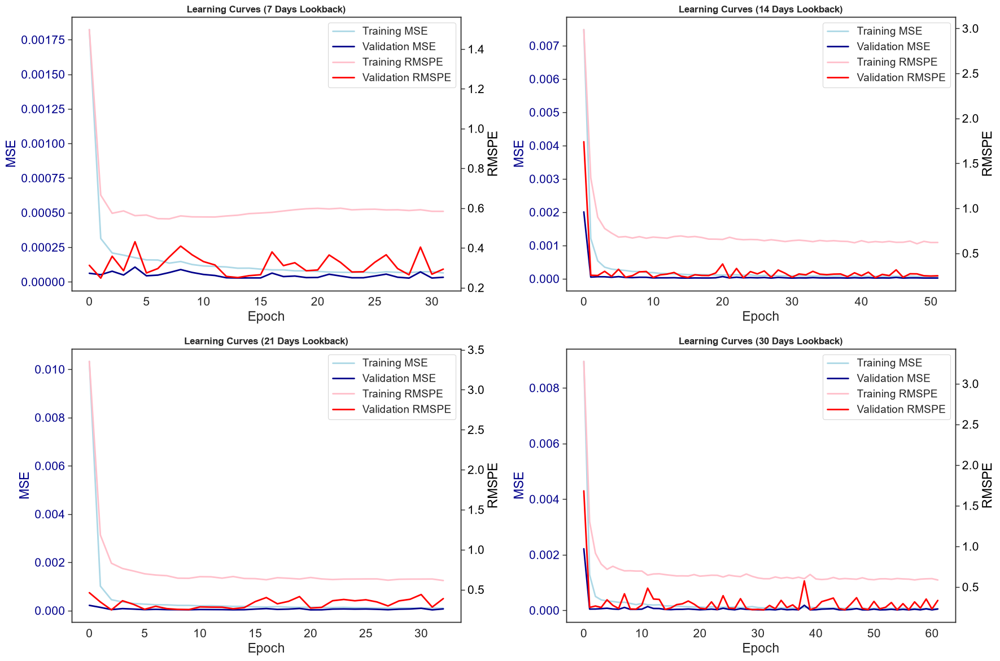

In [1266]:
# 1. Learning curves 2x2 grid
viz_grid_train_val_metrics(histories, days)

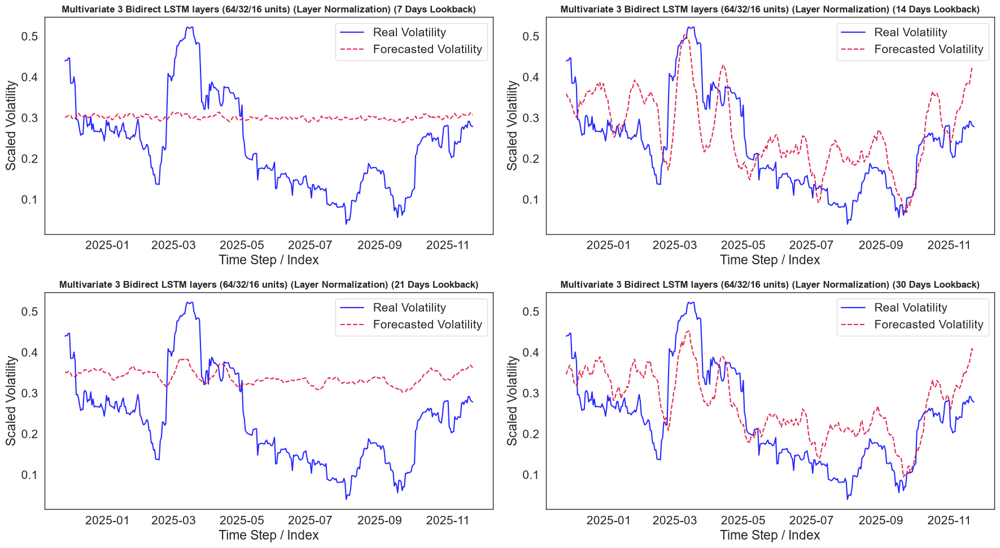

In [1267]:
# 2. Real vs Forecast 2x2 grid
viz_grid_predictions(predictions, y_val_scaled, days, model_title=MODEL_NAME)


In [1268]:
# 3. Log to global performance table
nn_perf_df = log_window_perf(
    y_true=y_val_scaled,
    predictions_dict=predictions,
    days_list=days,
    model_base_name=MODEL_NAME,
    target_df=nn_perf_df
)

print("\n=== UPDATED GLOBAL PERFORMANCE TABLE ===")
nn_perf_df


=== UPDATED GLOBAL PERFORMANCE TABLE ===


,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


Adding another LSTM layer helped reduce RMSE by a small margin (from 0.109233 to 0.077709), but RMSPE has actually significantly reduced more than 50% by reducing the validation split from 20% to 15% giving RMSPE of 0.367527 from 0.822295.

In [1270]:
# 1. Extract base model architecture name (strip ", n_past=...")
grid_df = nn_perf_df.copy()
grid_df['Architecture'] = grid_df['Model'].str.replace(r', n_past=\d+$', '', regex=True)

# 2. Pivot into a grid: rows = Architecture, columns = Metric & Lookback Window
perf_grid = grid_df.pivot(
    index='Architecture',
    columns='Lookback Window',
    values=['RMSPE', 'RMSE']
)

# 3. Preserve the original order of architectures as logged in the notebook
arch_order = grid_df['Architecture'].drop_duplicates().tolist()
perf_grid = perf_grid.loc[arch_order]

# 4. Format and highlight minimum errors per column
perf_grid.style.format("{:.4f}").highlight_min(axis=0, color='#d4edda')

In [1271]:
nn_perf_df

,Model,Lookback Window,RMSPE,RMSE
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
4,"1-Layered LSTM 20 units, n_past=7",7,1.250646,0.135956
5,"1-Layered LSTM 20 units, n_past=14",14,1.360875,0.147948
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
8,"2-Layered Bidirectional LSTMs (32/16 units), n_past=7",7,0.844823,0.099971
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797


## **Final Model**

In [1275]:
nn_perf_df.sort_values(by='RMSPE', ascending=True)

,Model,Lookback Window,RMSPE,RMSE
11,"2-Layered Bidirectional LSTMs (32/16 units), n_past=30",30,0.260476,0.053752
7,"1-Layered LSTM 20 units, n_past=30",30,0.332265,0.055795
9,"2-Layered Bidirectional LSTMs (32/16 units), n_past=14",14,0.341933,0.055797
0,"Simple Linear Regression Fully Connected Network, n_past=7",7,0.396381,0.062604
15,"1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units), n_past=30",30,0.412574,0.059494
2,"Simple Linear Regression Fully Connected Network, n_past=21",21,0.414480,0.069890
3,"Simple Linear Regression Fully Connected Network, n_past=30",30,0.445364,0.065866
6,"1-Layered LSTM 20 units, n_past=21",21,0.481316,0.067037
1,"Simple Linear Regression Fully Connected Network, n_past=14",14,0.521925,0.073853
10,"2-Layered Bidirectional LSTMs (32/16 units), n_past=21",21,0.553808,0.070603


In [1276]:
# Sort GARCH & Baseline models by Validation RMSPE (best at top)
garch_summary = (
    perf_df
    .sort_values(by='Validation RMSPE', ascending=True)
    .reset_index(drop=True)
)

# Display neatly with formatting and minimum error highlighting
(
    garch_summary.style
    .format({'Validation RMSPE': '{:.4f}', 'Validation RMSE': '{:.4f}'})
    .highlight_min(subset=['Validation RMSPE', 'Validation RMSE'], color='#d4edda')
    .set_caption("Baseline & GARCH Family Validation Error Comparison")
)

,Model,Validation RMSPE,Validation RMSE
0,"Bootstrap TARCH(3, 2, 0), Constant Mean, Skewt Dist",0.2071,0.0512
1,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.2461,0.0617
2,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.2470,0.0620
3,Random Walk Naive Forecasting,0.2682,0.0556
4,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.3247,0.0661
5,"GARCH(1,1), Constant Mean, Normal Dist",0.4996,0.1116
6,Mean Baseline,1.7737,0.1946


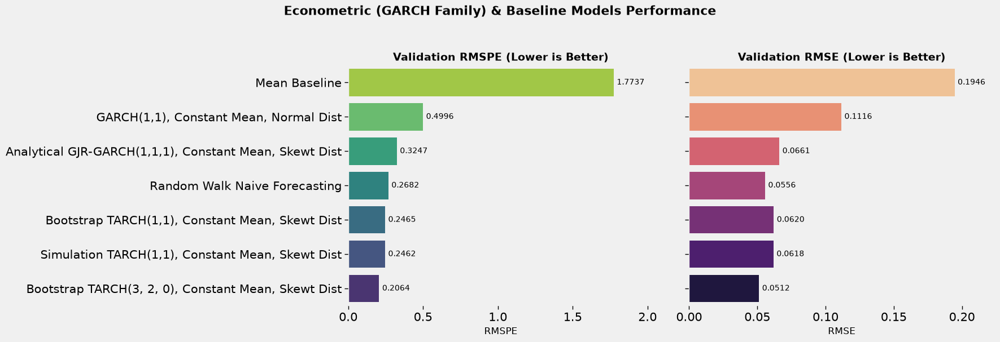

In [573]:
garch_sorted = perf_df.sort_values(by='Validation RMSPE', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 6), sharey=True)

# Left subplot: Validation RMSPE
sns.barplot(
    data=garch_sorted,
    x='Validation RMSPE',
    y='Model',
    palette='viridis_r',
    ax=axes[0]
)
axes[0].set_title('Validation RMSPE (Lower is Better)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('RMSPE', fontsize=12)
axes[0].set_ylabel('')
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f', padding=4, fontsize=10)
axes[0].set_xlim(0, garch_sorted['Validation RMSPE'].max() * 1.15)

# Right subplot: Validation RMSE
sns.barplot(
    data=garch_sorted,
    x='Validation RMSE',
    y='Model',
    palette='magma_r',
    ax=axes[1]
)
axes[1].set_title('Validation RMSE (Lower is Better)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('RMSE', fontsize=12)
axes[1].set_ylabel('')
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.4f', padding=4, fontsize=10)
axes[1].set_xlim(0, garch_sorted['Validation RMSE'].max() * 1.15)

plt.suptitle('Econometric (GARCH Family) & Baseline Models Performance', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [575]:
# Get the best-performing lookback window for each NN architecture
best_nn = (
    nn_perf_df
    .sort_values('RMSPE')
    .groupby(nn_perf_df['Model'].str.replace(r', n_past=\d+$', '', regex=True), as_index=False)
    .first()
    .rename(columns={'RMSPE': 'Validation RMSPE', 'RMSE': 'Validation RMSE'})
    [['Model', 'Validation RMSPE', 'Validation RMSE']]
)

# Combine with GARCH & Baseline models
final_leaderboard = (
    pd.concat([perf_df, best_nn], ignore_index=True)
    .sort_values(by='Validation RMSPE', ascending=True)
    .reset_index(drop=True)
)

(
    final_leaderboard.style
    .format({'Validation RMSPE': '{:.4f}', 'Validation RMSE': '{:.4f}'})
    .highlight_min(subset=['Validation RMSPE', 'Validation RMSE'], color='#d4edda')
    .set_caption("Final Validation Leaderboard: Econometric (GARCH) vs. Neural Networks")
)

,Model,Validation RMSPE,Validation RMSE
0,"Bootstrap TARCH(3, 2, 0), Constant Mean, Skewt Dist",0.2064,0.0512
1,"Simulation TARCH(1,1), Constant Mean, Skewt Dist",0.2462,0.0618
2,"Bootstrap TARCH(1,1), Constant Mean, Skewt Dist",0.2465,0.0620
3,"2-Layered Bidirectional LSTMs (32/16 units), n_past=30",0.2549,0.0537
4,Random Walk Naive Forecasting,0.2682,0.0556
5,"Analytical GJR-GARCH(1,1,1), Constant Mean, Skewt Dist",0.3247,0.0661
6,"1 Conv1D 2-Layered Bidirectional LSTMs (32/16 units), n_past=30",0.3332,0.0567
7,"Simple Linear Regression Fully Connected Network, n_past=30",0.4516,0.0664
8,"Stacked Bi-LSTM (Tuned LR=1e-4), n_past=30",0.4516,0.0664
9,"GARCH(1,1), Constant Mean, Normal Dist",0.4996,0.1116


For this final model, I'll re-create the same architecture as model #12 (Multivariate Bidirectional LSTM with 2 layers of 32/16 units) and a lookback window `n_past = 30` and `batch_size = 64`. However, I'll extend the training to include the validation set as well. This is important in time series data since the more recent time steps would most likely carry more relevant information for successful forecasting than data from a year ago.

Since the validation MSE and RMSPE lines have been very unstable, I will extend the training epochs to 500 to seee if that could help capture better weights.

It should be stressed that the model was trained on both the training and validation data this time. Therefore it'd naturally trace the target more closely up until the third week of July 2021 where the validation ends. 

# **Conclusion**

In terms of performance on the validation set (7/23/2020 to 7/25/2021), my final LSTM model has an RMSPE of 0.156677, which is roughly 4.42% better than the best performing variant of the GARCH models found - TARCH(1,2) with an RMSPE of 0.200954. Traders does not need to make perfectly accurate forecast to have a positive expectation when participating in the markets, they just need to make a forecast that is **both correct and more correct than the general consensus**. With GARCH still being the most popular volatility forecasting model, Multivariate LSTM could potentially give investors an advantage in terms of higher forecasting accuracy.

The final LSTM model has an RMSPE of 0.0534 on the Test set (which is the most recent 30 days of which future volatility data is available for comparison). Since RMSPE indicates the average magnitude of the error in relation to the actual values, an RMSPE of 0.0534 would translate to a magnitude accuracy of 94.65% on the average 7-day horizon daily volatility forecasting within the period of 07/24/2021 to 08/22/2021.  

However, since financial time series data are constantly evolving, no model would be able to consistently forecast with high accuracy level forever. The average lifetime of a model is between 6 months to 5 years, and there's a phenomenon in quant trading that is called **alpha decay**, which is the loss in predictive power of an alpha model over time. In addition, according to Sinclair (2020), researchers have found that the publication of a new "edge" or anomaly in the markets lessens its returns by up to 58%.  

These models therfore require constant tweaking and tuning based on the most recent information available to make sure they stay up-to-date and learn to evolve with the markets. 

# References:

1. Géron, A. (2019). *In Hands-on machine learning with Scikit-Learn & TensorFlow: concepts, tools, and techniques to build intelligent systems.* O'Reilly Media, Inc.

2. Sinclair, E. (2020). *Positional option trading: An advanced guide.* John Wiley &amp; Sons. 

3. https://algotrading101.com/learn/yfinance-guide/ 

4. https://www.coursera.org/learn/tensorflow-sequences-time-series-and-prediction/supplement/DM4fi/convolutional-neural-networks-course

5. https://insights.deribit.com/options-course/

6. https://arch.readthedocs.io/en/latest/univariate/univariate_volatility_forecasting.html 

7. https://www.investopedia.com/terms/v/vix.asp 

8. https://www.hindawi.com/journals/complexity/2021/6647534/ 

9. https://github.com/ritvikmath/Time-Series-Analysis/blob/master/GARCH%20Stock%20Modeling.ipynb

10. https://github.com/ritvikmath/Time-Series-Analysis/blob/master/GARCH%20Model.ipynb

11. https://www.kaggle.com/c/optiver-realized-volatility-prediction 

12. https://www.youtube.com/watch?v=NKHQiN-08S8

13. https://goldinlocks.github.io/ARCH_GARCH-Volatility-Forecasting/ 

14. https://towardsdatascience.com/time-series-analysis-on-multivariate-data-in-tensorflow-2f0591088502 

15. https://deepmind.com/blog/article/wavenet-generative-model-raw-audio 

16. https://github.com/philipperemy/keras-tcn 

17. http://users.metu.edu.tr/ozancan/ARCHGARCHTutorial.html

18. https://towardsdatascience.com/8-commonly-used-pandas-display-options-you-should-know-a832365efa95